In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import f1_score, confusion_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from  lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import cross_val_score
from sklearn.metrics import accuracy_score
import optuna
import shap
import pprint
shap.initjs()




In [2]:
df = pd.read_excel("E Commerce Dataset.xlsx", sheet_name = 'E Comm')
df.head()

,CustomerID,Churn,Tenure,PreferredLoginDevice,CityTier,WarehouseToHome,PreferredPaymentMode,Gender,HourSpendOnApp,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount
0,50001,1,4.0,Mobile Phone,3,6.0,Debit Card,Female,3.0,3,Laptop & Accessory,2,Single,9,1,11.0,1.0,1.0,5.0,159.93
1,50002,1,NaN,Phone,1,8.0,UPI,Male,3.0,4,Mobile,3,Single,7,1,15.0,0.0,1.0,0.0,120.90
2,50003,1,NaN,Phone,1,30.0,Debit Card,Male,2.0,4,Mobile,3,Single,6,1,14.0,0.0,1.0,3.0,120.28
3,50004,1,0.0,Phone,3,15.0,Debit Card,Male,2.0,4,Laptop & Accessory,5,Single,8,0,23.0,0.0,1.0,3.0,134.07
4,50005,1,0.0,Phone,1,12.0,CC,Male,NaN,3,Mobile,5,Single,3,0,11.0,1.0,1.0,3.0,129.60


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5630 entries, 0 to 5629
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   CustomerID                   5630 non-null   int64  
 1   Churn                        5630 non-null   int64  
 2   Tenure                       5366 non-null   float64
 3   PreferredLoginDevice         5630 non-null   object 
 4   CityTier                     5630 non-null   int64  
 5   WarehouseToHome              5379 non-null   float64
 6   PreferredPaymentMode         5630 non-null   object 
 7   Gender                       5630 non-null   object 
 8   HourSpendOnApp               5375 non-null   float64
 9   NumberOfDeviceRegistered     5630 non-null   int64  
 10  PreferedOrderCat             5630 non-null   object 
 11  SatisfactionScore            5630 non-null   int64  
 12  MaritalStatus                5630 non-null   object 
 13  NumberOfAddress   

In [4]:
df.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
CustomerID,5630.0,52815.500000,1625.385339,50001.0,51408.25,52815.50,54222.7500,55630.00
Churn,5630.0,0.168384,0.374240,0.0,0.00,0.00,0.0000,1.00
Tenure,5366.0,10.189899,8.557241,0.0,2.00,9.00,16.0000,61.00
CityTier,5630.0,1.654707,0.915389,1.0,1.00,1.00,3.0000,3.00
WarehouseToHome,5379.0,15.639896,8.531475,5.0,9.00,14.00,20.0000,127.00
HourSpendOnApp,5375.0,2.931535,0.721926,0.0,2.00,3.00,3.0000,5.00
NumberOfDeviceRegistered,5630.0,3.688988,1.023999,1.0,3.00,4.00,4.0000,6.00
SatisfactionScore,5630.0,3.066785,1.380194,1.0,2.00,3.00,4.0000,5.00
NumberOfAddress,5630.0,4.214032,2.583586,1.0,2.00,3.00,6.0000,22.00
Complain,5630.0,0.284902,0.451408,0.0,0.00,0.00,1.0000,1.00


In [5]:
df.describe(include='O').transpose()

,count,unique,top,freq
PreferredLoginDevice,5630,3,Mobile Phone,2765
PreferredPaymentMode,5630,7,Debit Card,2314
Gender,5630,2,Male,3384
PreferedOrderCat,5630,6,Laptop & Accessory,2050
MaritalStatus,5630,3,Married,2986


In [6]:
df.duplicated().sum()

0

no duplicated values on the dataset

In [7]:
df.columns[df.isnull().any()]

Index(['Tenure', 'WarehouseToHome', 'HourSpendOnApp',
       'OrderAmountHikeFromlastYear', 'CouponUsed', 'OrderCount',
       'DaySinceLastOrder'],
      dtype='object')

columns with null values

In [8]:
df.isnull().sum()[df.isnull().sum()>0]



Tenure                         264
WarehouseToHome                251
HourSpendOnApp                 255
OrderAmountHikeFromlastYear    265
CouponUsed                     256
OrderCount                     258
DaySinceLastOrder              307
dtype: int64

In [9]:
round(df.isnull().sum()[df.isnull().sum()>0]/df.shape[0]*100, 2)

Tenure                         4.69
WarehouseToHome                4.46
HourSpendOnApp                 4.53
OrderAmountHikeFromlastYear    4.71
CouponUsed                     4.55
OrderCount                     4.58
DaySinceLastOrder              5.45
dtype: float64

In [10]:
total_na = df.isnull().sum().sum()
print(f"Total missing values: {total_na} ({ round((total_na/df.shape[0])*100, 2) }%)")


Total missing values: 1856 (32.97%)


In [11]:
#count the total number of missing values in the dataset
print(f'The number of missing values: {df.isnull().sum().sum()}')
#count the number of rows with missing values
print(f'The number of rows with missing values: {df[df.isnull().any(axis=1)].shape[0]}')

The number of missing values: 1856
The number of rows with missing values: 1856


<Axes: >

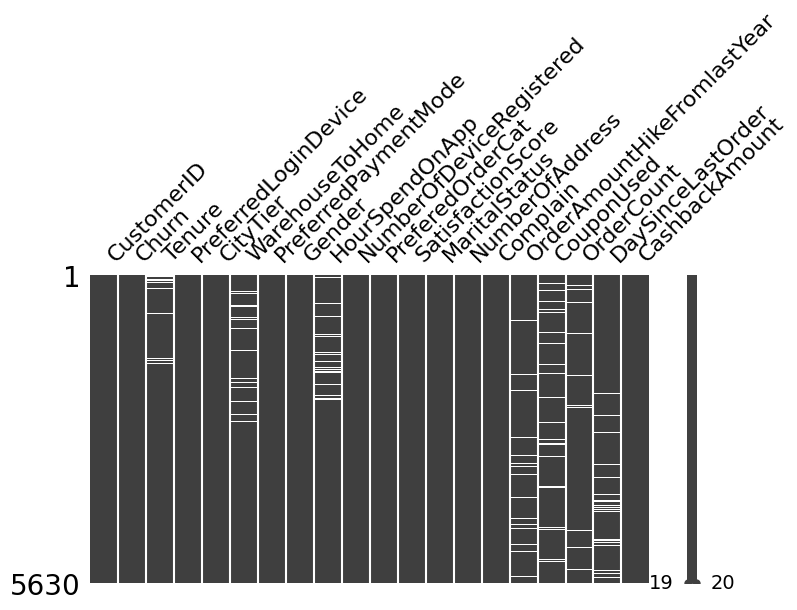

In [12]:
msno.matrix(df,figsize=(8,4))

In [13]:
print(df.sort_values(by='CashbackAmount',ascending=False))

      CustomerID  Churn  Tenure PreferredLoginDevice  CityTier  \
4350       54351      0    26.0         Mobile Phone         1   
2880       52881      0    26.0         Mobile Phone         1   
4906       54907      0    15.0             Computer         1   
3436       53437      0    15.0             Computer         1   
5011       55012      0    30.0         Mobile Phone         1   
...          ...    ...     ...                  ...       ...   
1300       51301      0     6.0         Mobile Phone         1   
1255       51256      0     8.0         Mobile Phone         3   
1176       51177      0    30.0             Computer         3   
101        50102      0    10.0             Computer         3   
1026       51027      0     1.0         Mobile Phone         1   

      WarehouseToHome PreferredPaymentMode  Gender  HourSpendOnApp  \
4350              7.0           Debit Card    Male             4.0   
2880              7.0           Debit Card    Male             4.0 

<Axes: >

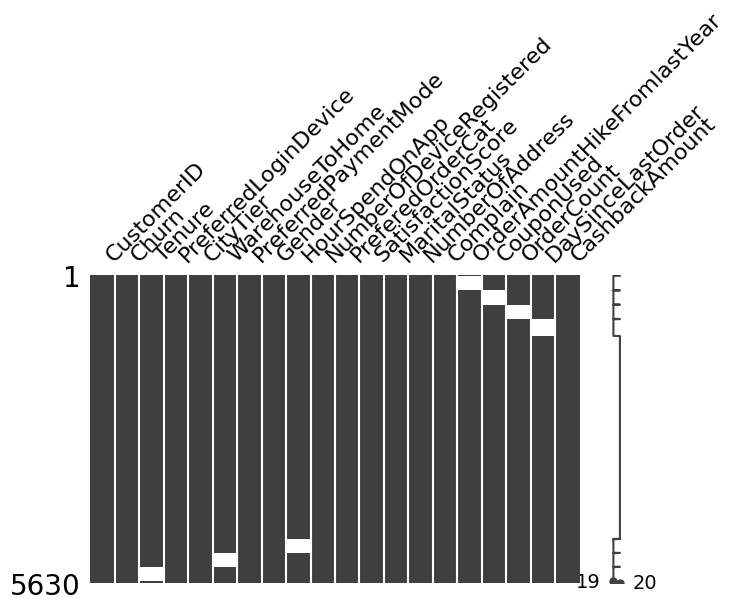

In [14]:
num_cols=[ 'Tenure', 'WarehouseToHome',
       'HourSpendOnApp', 'NumberOfDeviceRegistered',
       'NumberOfAddress', 'OrderAmountHikeFromlastYear',
       'CouponUsed', 'OrderCount', 'DaySinceLastOrder', 'CashbackAmount',]
df_num=df[num_cols]

msno.matrix(df.sort_values(by='CashbackAmount',ascending=False), figsize=(7,4))

In [15]:
df_num=df[num_cols]
df_num.head()

,Tenure,WarehouseToHome,HourSpendOnApp,NumberOfDeviceRegistered,NumberOfAddress,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount
0,4.0,6.0,3.0,3,9,11.0,1.0,1.0,5.0,159.93
1,NaN,8.0,3.0,4,7,15.0,0.0,1.0,0.0,120.90
2,NaN,30.0,2.0,4,6,14.0,0.0,1.0,3.0,120.28
3,0.0,15.0,2.0,4,8,23.0,0.0,1.0,3.0,134.07
4,0.0,12.0,NaN,3,3,11.0,1.0,1.0,3.0,129.60


IndexError: single positional indexer is out-of-bounds

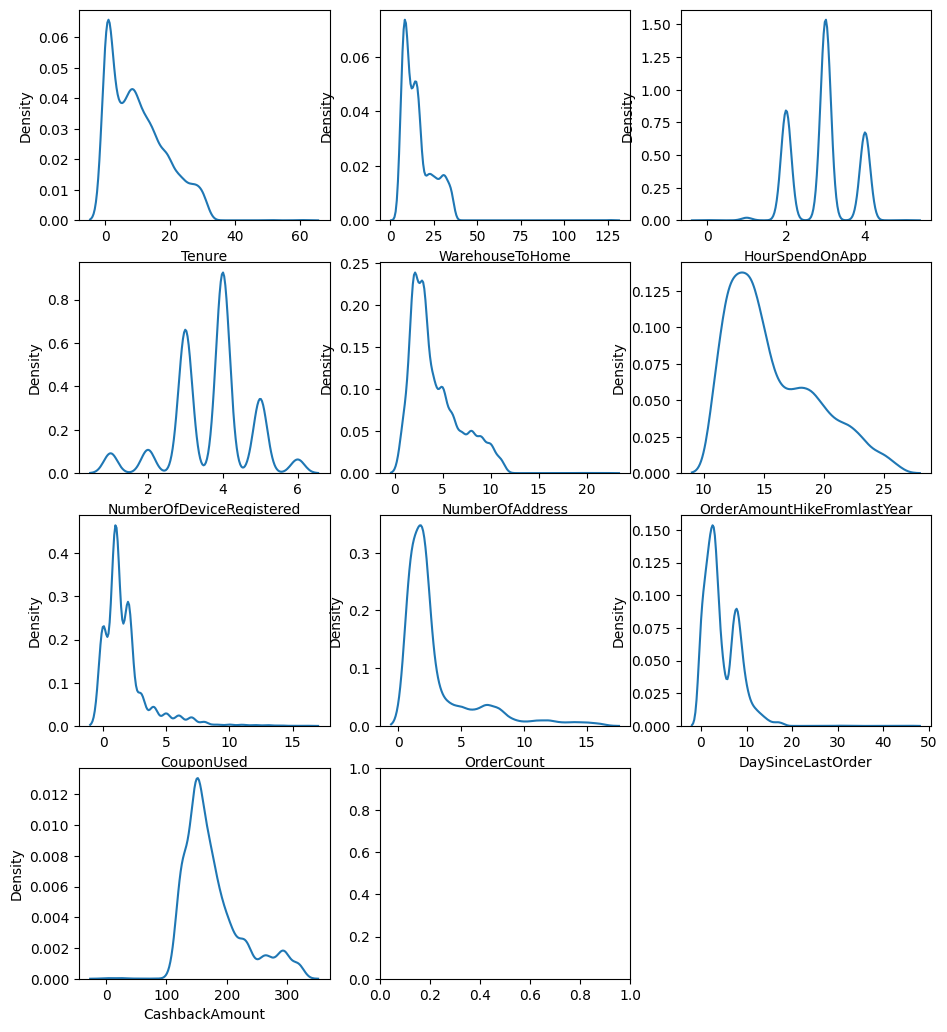

In [16]:
fig_kd = plt.figure(figsize=(11,29))
for i in range(len(df_num)):
    fig_kd.add_subplot(9,3,i+1)
    sns.kdeplot(x=df_num.iloc[:,i])

plt.tight_layout()
plt.show()

In total there are 1856 missing values, and there are also 1856 rows with missing values, meaning that each of the missing value is on a different row, and no row has more than one missing value.

So if we drop all the rows with missing values we would be dropping 1856 rows that is 32.97 percent of the dataset and will cause a data loss,the number of missing values per column does not exceed 6% and there found randomly across the dataset (MAR) there is no pattern for missing values .
After analyzing the missing data patterns, we found that the missingness depends on CashbackAmount, a fully observed feature. This means the missing values are Missing At Random (MAR), which allows us to use model-based imputations reliably.

Since about one-third of rows contain missing values, dropping them would severely reduce the dataset size, so imputation is necessary.

Simple imputations such as mean or median are not ideal. Mean imputation fails because many variables are skewed and it distorts the distribution. Median imputation handles skewness better but still ignores relationships between variables and reduces the multivariate structure of the data.

KNN imputation is a better alternative because it imputes values based on similar rows. However, it is computationally expensive, sensitive to scaling, and still does not fully preserve feature correlations.

The best method for this dataset is the Iterative Imputer (MICE). It builds predictive models for each variable with missing values, using all other features as inputs. This approach naturally handles MAR data and preserves correlations, variance, and the overall distribution much better than simpler methods.

Therefore, Iterative Imputer is the most appropriate choice for our dataset.we will use in our pipeline before training our models


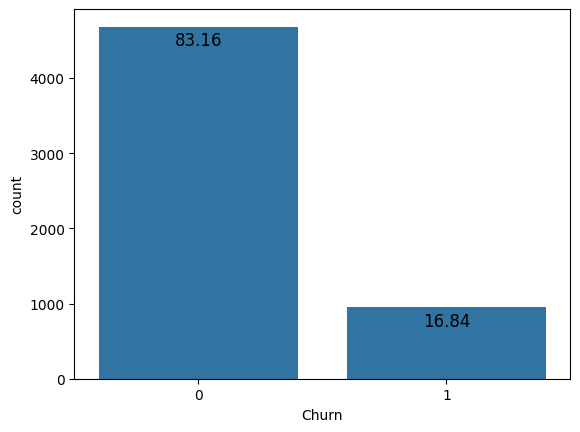

In [17]:
ax = sns.countplot(x='Churn', data=df)
for a in ax.patches:
    ax.annotate(format((a.get_height()/5630)*100,'.2f'), (a.get_x() + a.get_width()/2., a.get_height()),\
                ha='center',va='center',size=12,xytext=(0, -10),textcoords='offset points')
plt.show()

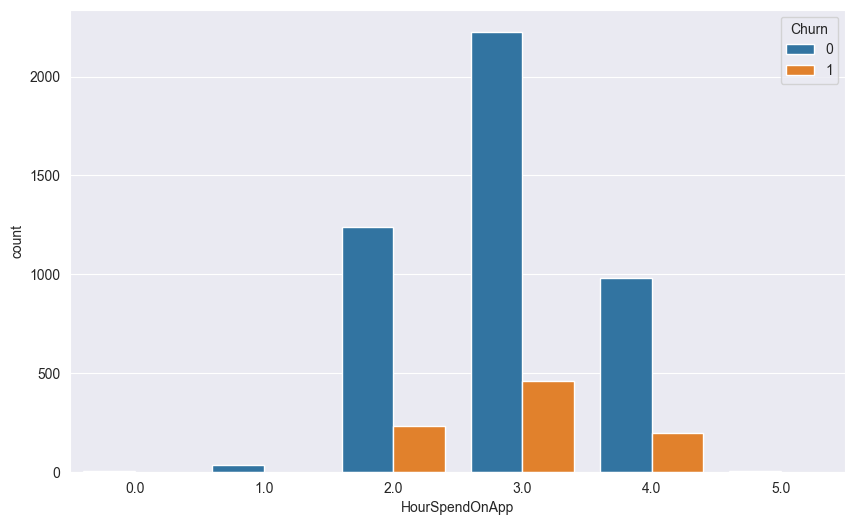

In [ ]:
plt.figure(figsize=(10,6))
sns.countplot(x='HourSpendOnApp',hue='Churn', data=df)
plt.show()

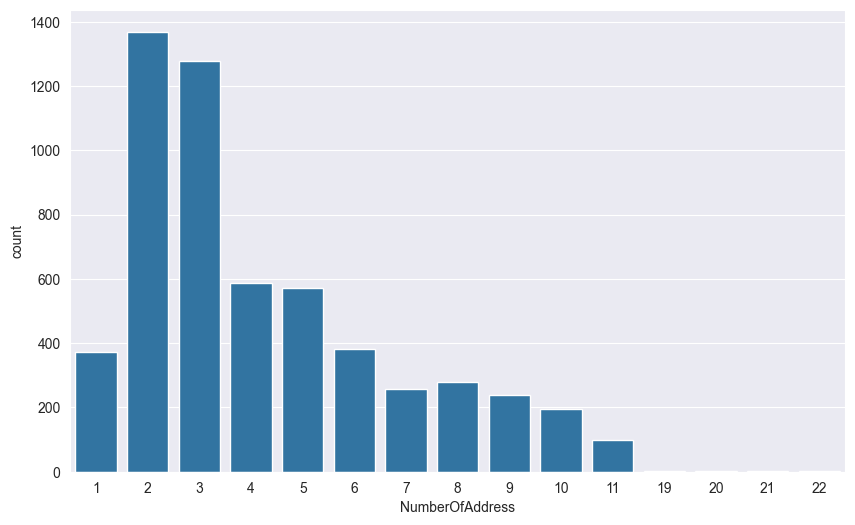

In [ ]:
plt.figure(figsize=(10,6))
sns.countplot(x='NumberOfAddress', data=df)
plt.show()

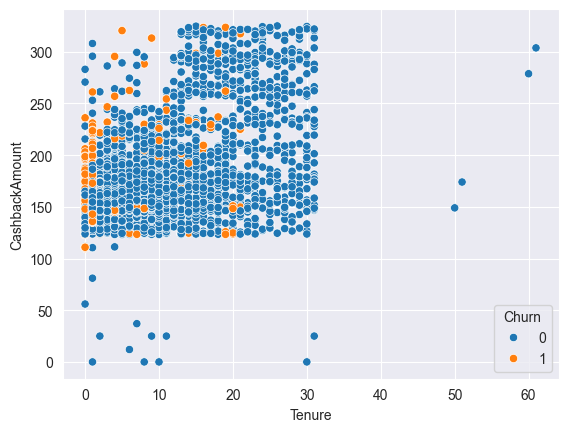

In [ ]:
sns.scatterplot(x='Tenure', y='CashbackAmount', hue='Churn', data=df)
plt.show()

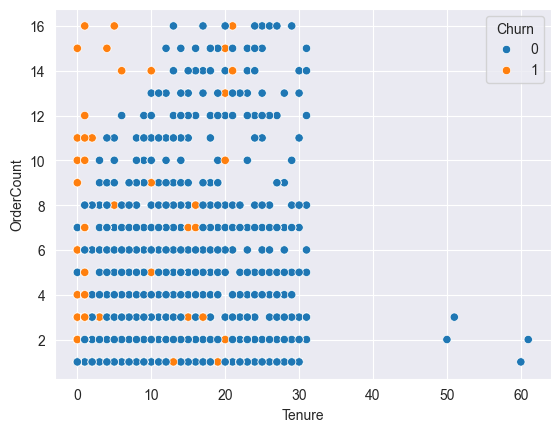

In [ ]:
sns.scatterplot(x='Tenure', y='OrderCount', hue='Churn', data=df)
plt.show()

we see that customers of high tenure have low order count

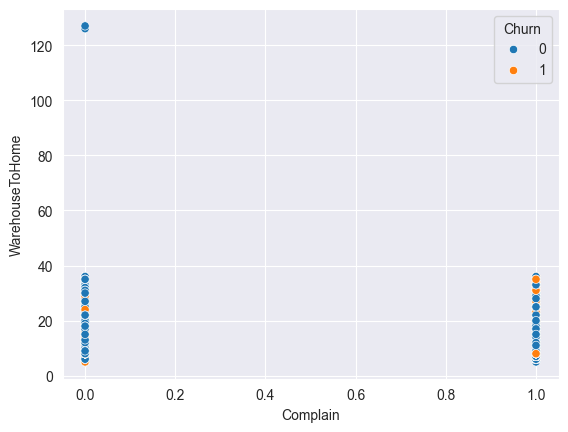

In [ ]:
sns.scatterplot(y='WarehouseToHome', x='Complain',hue='Churn', data=df)
plt.show()

distnance between warehouse and customer has no effect on their churn and also customers do not complin about the long distance .

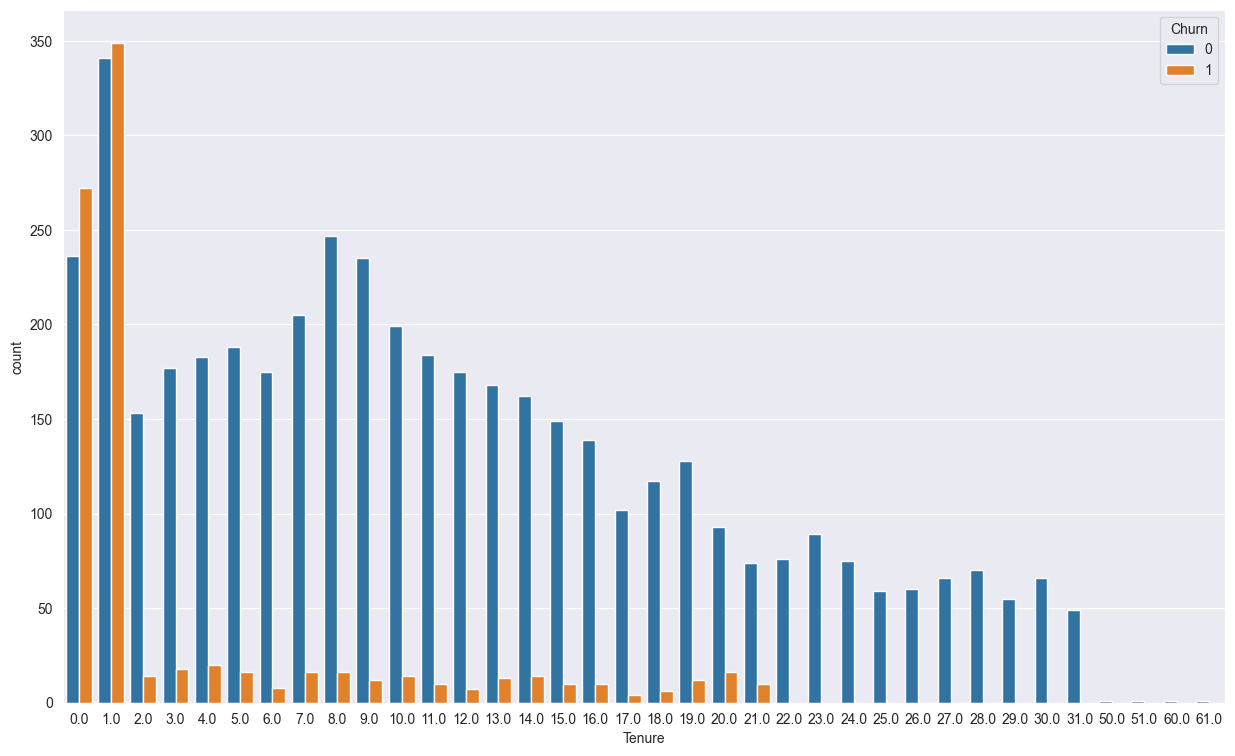

In [ ]:
plt.figure(figsize=(15,9))
sns.countplot(x='Tenure',hue='Churn', data=df)
plt.show()

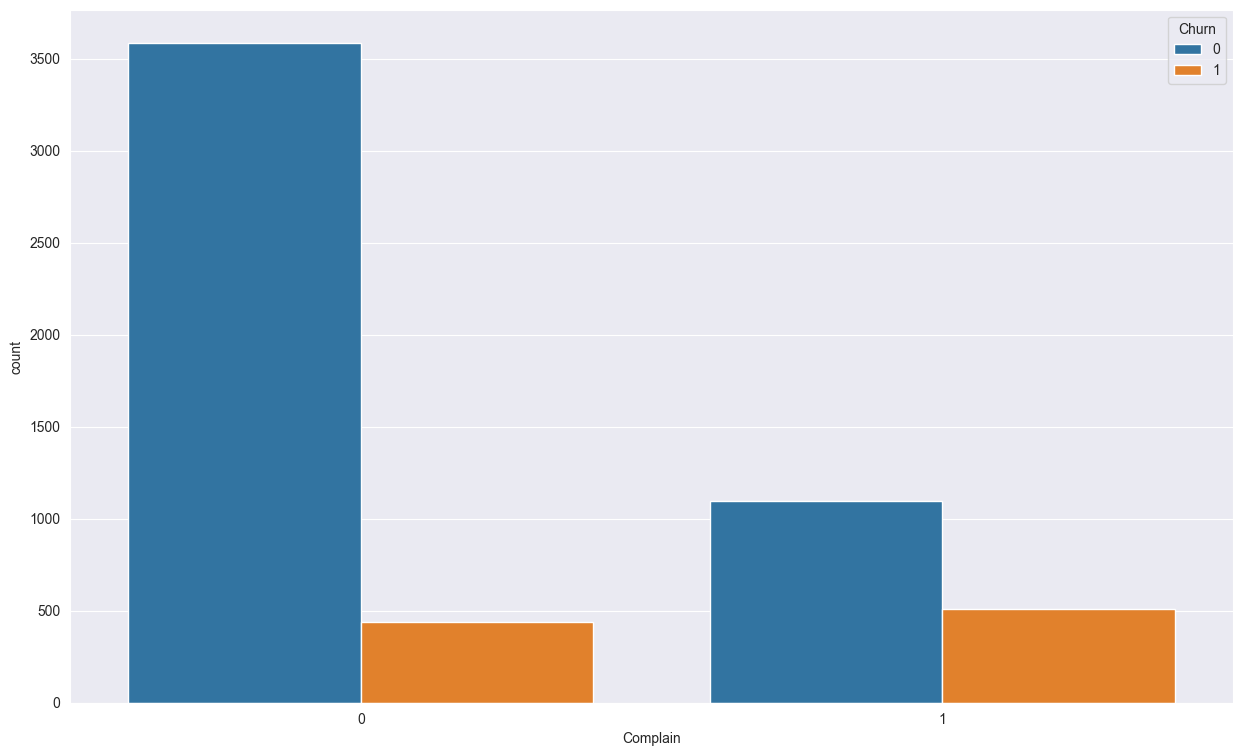

In [ ]:
plt.figure(figsize=(15,9))
sns.countplot(x='Complain',hue='Churn', data=df)
plt.show()

unlike Warehouse to home Tenure is a strong indicator of churn

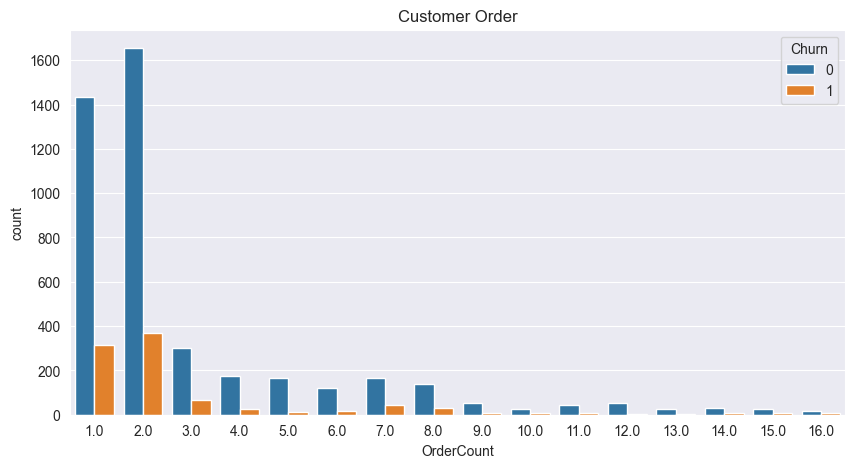

In [ ]:
plt.figure(figsize=(10,5))
sns.countplot(x=df['OrderCount'], hue=df['Churn'])
plt.title('Customer Order')
plt.show()

most customers make one or two orders also they ere the one who ares most likely to churn

one_hot encoding is the way to go here since the columns are nominal (no ordinal columns) and also there is few unique values which won't be problem for dimension explosivity.

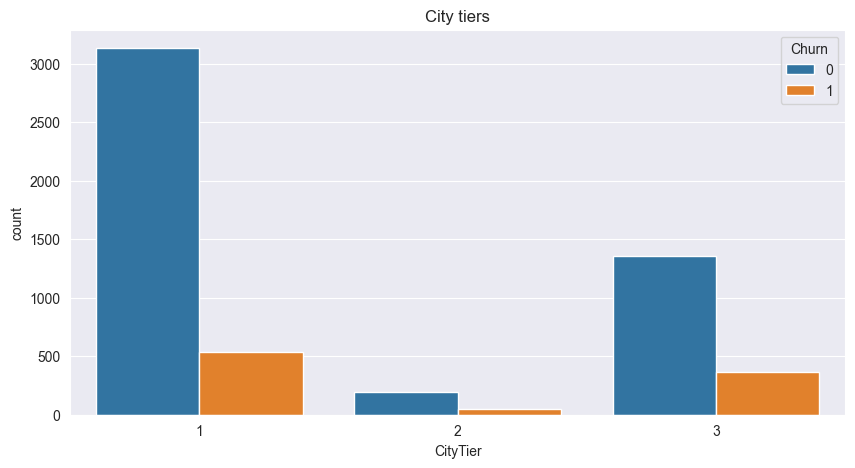

In [ ]:
plt.figure(figsize=(10,5))
sns.countplot(x=df['CityTier'], hue=df['Churn'])
plt.title('City tiers')
plt.show()

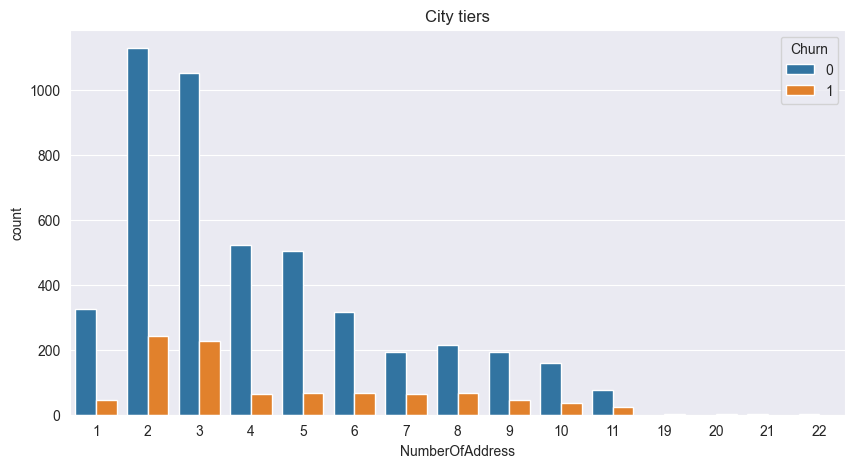

In [ ]:
plt.figure(figsize=(10,5))
sns.countplot(x=df['NumberOfAddress'], hue=df['Churn'])
plt.title('City tiers')
plt.show()

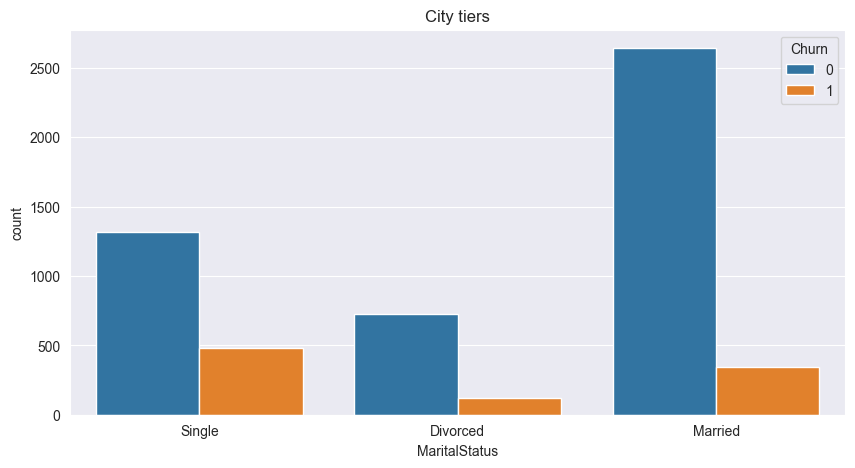

In [ ]:
plt.figure(figsize=(10,5))
sns.countplot(x=df['MaritalStatus'], hue=df['Churn'])
plt.title('City tiers')
plt.show()

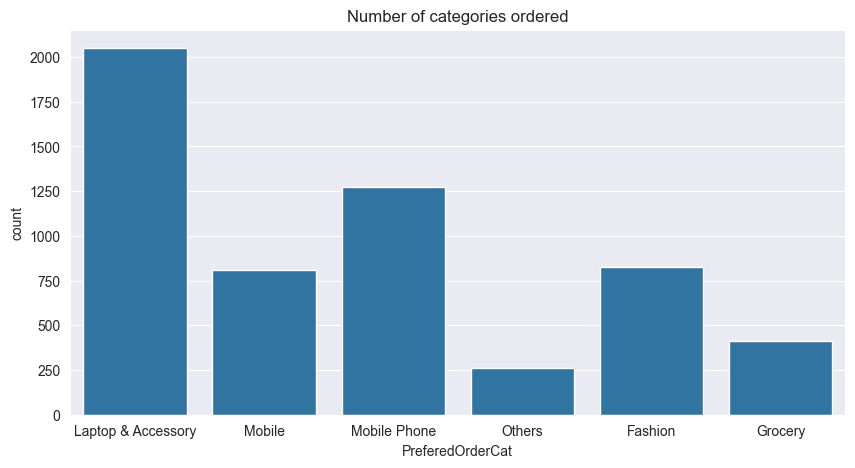

In [ ]:
plt.figure(figsize=(10,5))
sns.countplot(x=df['PreferedOrderCat'])
plt.title('Number of categories ordered')
plt.show()

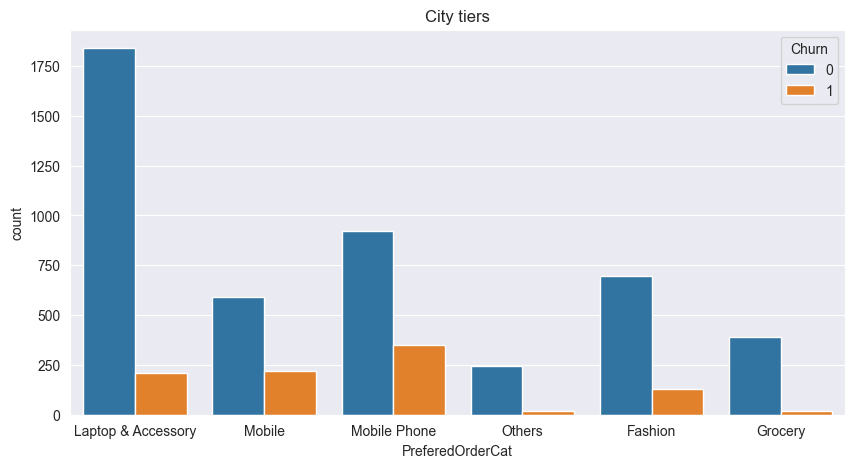

In [ ]:
plt.figure(figsize=(10,5))
sns.countplot(x=df['PreferedOrderCat'], hue=df['Churn'])
plt.title('City tiers')
plt.show()

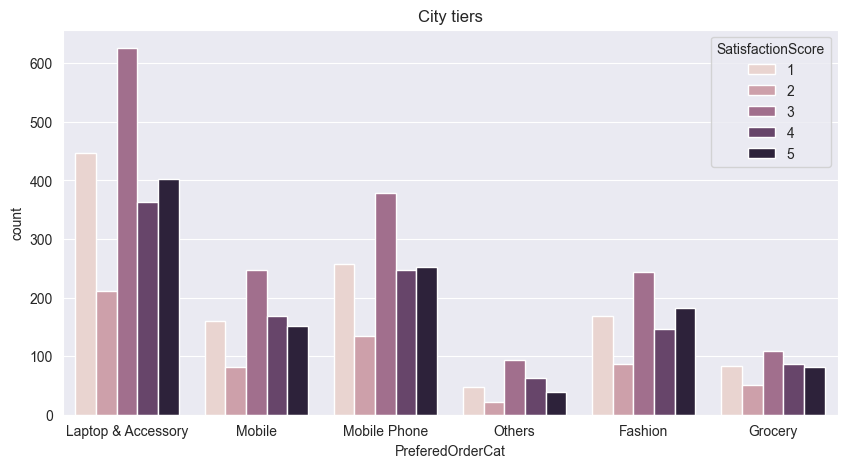

In [ ]:
plt.figure(figsize=(10,5))
sns.countplot(x=df['PreferedOrderCat'], hue=df['SatisfactionScore'])
plt.title('City tiers')
plt.show()

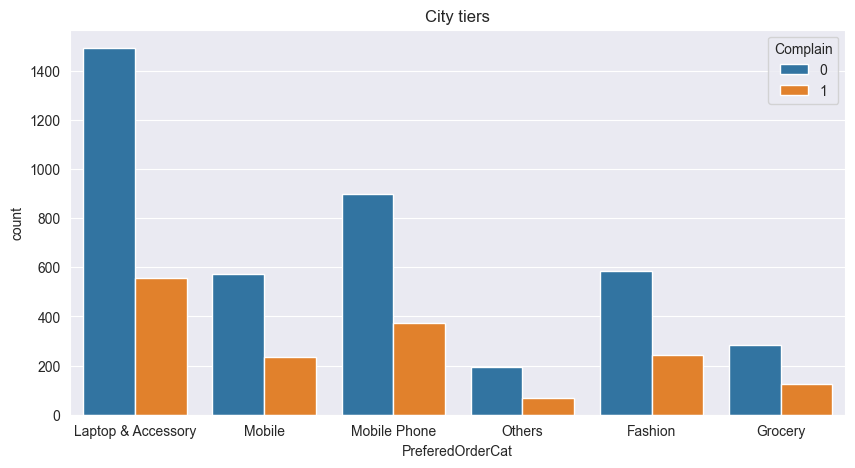

In [ ]:
plt.figure(figsize=(10,5))
sns.countplot(x=df['PreferedOrderCat'], hue=df['Complain'])
plt.title('City tiers')
plt.show()

In [ ]:
df.describe(include='O').transpose()

,count,unique,top,freq
PreferredLoginDevice,5630,3,Mobile Phone,2765
PreferredPaymentMode,5630,7,Debit Card,2314
Gender,5630,2,Male,3384
PreferedOrderCat,5630,6,Laptop & Accessory,2050
MaritalStatus,5630,3,Married,2986


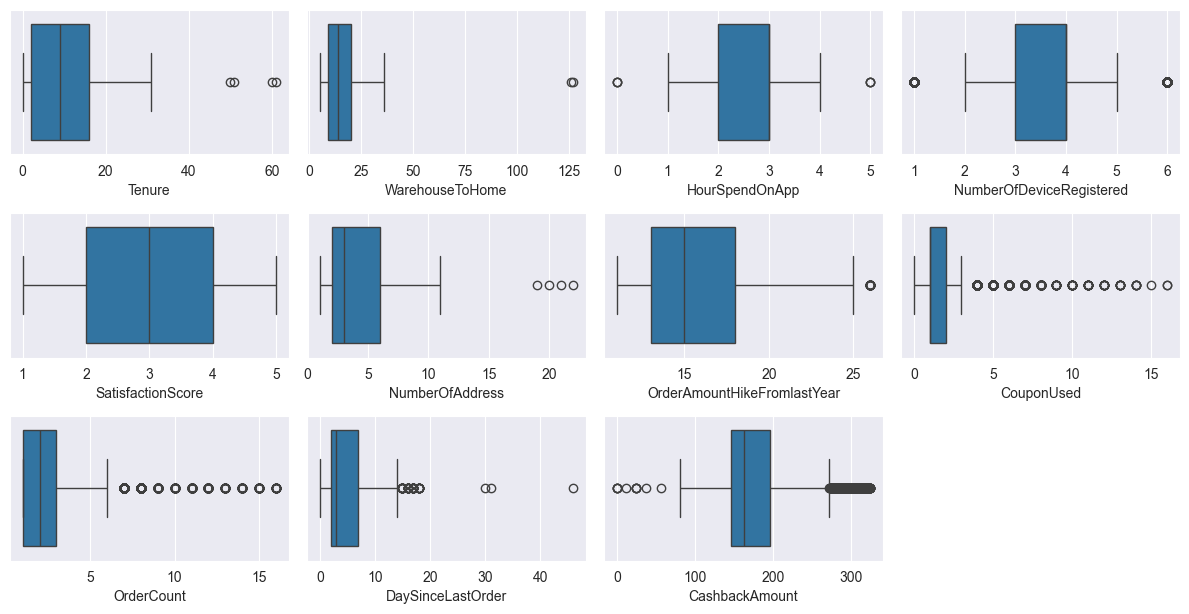

In [ ]:
fig = plt.figure(figsize=(12,18))
for i in range(len(df_num.columns)):
    fig.add_subplot(9,4,i+1)
    sns.boxplot(x=df_num.iloc[:,i])

plt.tight_layout()
plt.show()

as we can see there is some outliers in the dataset especially in some columns like WarehouseToHome,DaySinceLastOrder and CashBackamount,these outliers could be real and important data not just errors or abnormal values so we can't risk getting rid of these values, also outliers dont have huge impact on the tree models which seems like the way to go for our modelisation

In [ ]:
def handle_outliers(df , column_name):
  Q1 = df[column_name].quantile(0.25)
  Q3 = df[column_name].quantile(0.75)
  IQR = Q3 - Q1
  Upper = Q3 + IQR * 1.5
  lower = Q1 - IQR * 1.5
  df_new= df[ (df[column_name] > lower) & (df[column_name] < Upper) ]

  return df_new

In [ ]:
cols_outliers = ['Tenure' , 'WarehouseToHome' , 'NumberOfAddress' , 'DaySinceLastOrder' , 'HourSpendOnApp' , 'NumberOfDeviceRegistered']
df_clean=df.copy()
for col in cols_outliers:
    df_clean = handle_outliers(df_clean , col)

df_clean.head(4)

,CustomerID,Churn,Tenure,PreferredLoginDevice,CityTier,WarehouseToHome,PreferredPaymentMode,Gender,HourSpendOnApp,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount
0,50001,1,4.0,Mobile Phone,3,6.0,Debit Card,Female,3.0,3,Laptop & Accessory,2,Single,9,1,11.0,1.0,1.0,5.0,159.93
3,50004,1,0.0,Phone,3,15.0,Debit Card,Male,2.0,4,Laptop & Accessory,5,Single,8,0,23.0,0.0,1.0,3.0,134.07
5,50006,1,0.0,Computer,1,22.0,Debit Card,Female,3.0,5,Mobile Phone,5,Single,2,1,22.0,4.0,6.0,7.0,139.19
10,50011,1,4.0,Mobile Phone,1,18.0,Cash on Delivery,Female,2.0,3,Others,3,Divorced,2,0,NaN,9.0,15.0,8.0,295.45


In [ ]:
df.select_dtypes(include='number').columns

Index(['CustomerID', 'Churn', 'Tenure', 'CityTier', 'WarehouseToHome',
       'HourSpendOnApp', 'NumberOfDeviceRegistered', 'SatisfactionScore',
       'NumberOfAddress', 'Complain', 'OrderAmountHikeFromlastYear',
       'CouponUsed', 'OrderCount', 'DaySinceLastOrder', 'CashbackAmount'],
      dtype='object')

In [ ]:
num_cols=[ 'Churn', 'Tenure', 'CityTier', 'WarehouseToHome',
       'HourSpendOnApp', 'NumberOfDeviceRegistered', 'SatisfactionScore',
       'NumberOfAddress', 'Complain', 'OrderAmountHikeFromlastYear',
       'CouponUsed', 'OrderCount', 'DaySinceLastOrder', 'CashbackAmount',]



In [ ]:
corr=df[num_cols].corr()
corr

,Churn,Tenure,CityTier,WarehouseToHome,HourSpendOnApp,NumberOfDeviceRegistered,SatisfactionScore,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount
Churn,1.000000,-0.349408,0.084703,0.076630,0.018675,0.107939,0.105481,0.043931,0.250188,-0.010058,-0.008264,-0.028697,-0.160757,-0.154118
Tenure,-0.349408,1.000000,-0.060688,-0.018218,-0.021226,-0.023983,-0.013903,0.237666,-0.021268,0.005825,0.129035,0.186403,0.184552,0.476380
CityTier,0.084703,-0.060688,1.000000,0.010624,-0.009150,0.027934,-0.011554,-0.029440,0.003375,-0.031408,0.021456,0.033388,0.017525,0.055746
WarehouseToHome,0.076630,-0.018218,0.010624,1.000000,0.060990,0.019071,0.007722,-0.011020,0.028696,0.038795,-0.003935,0.002681,0.017829,-0.009200
HourSpendOnApp,0.018675,-0.021226,-0.009150,0.060990,1.000000,0.316800,0.031858,0.145126,0.006976,0.106843,0.191528,0.109575,0.075716,0.121490
NumberOfDeviceRegistered,0.107939,-0.023983,0.027934,0.019071,0.316800,1.000000,-0.017228,0.084997,0.003407,0.069475,0.151685,0.103464,0.018208,0.137183
SatisfactionScore,0.105481,-0.013903,-0.011554,0.007722,0.031858,-0.017228,1.000000,0.053583,-0.031115,-0.027730,0.017936,0.019764,0.032082,0.003473
NumberOfAddress,0.043931,0.237666,-0.029440,-0.011020,0.145126,0.084997,0.053583,1.000000,-0.026399,0.015533,0.042120,-0.007609,-0.064847,0.186688
Complain,0.250188,-0.021268,0.003375,0.028696,0.006976,0.003407,-0.031115,-0.026399,1.000000,-0.004529,-0.008174,-0.019307,-0.043546,0.000525
OrderAmountHikeFromlastYear,-0.010058,0.005825,-0.031408,0.038795,0.106843,0.069475,-0.027730,0.015533,-0.004529,1.000000,0.033201,0.023101,0.006003,0.017869


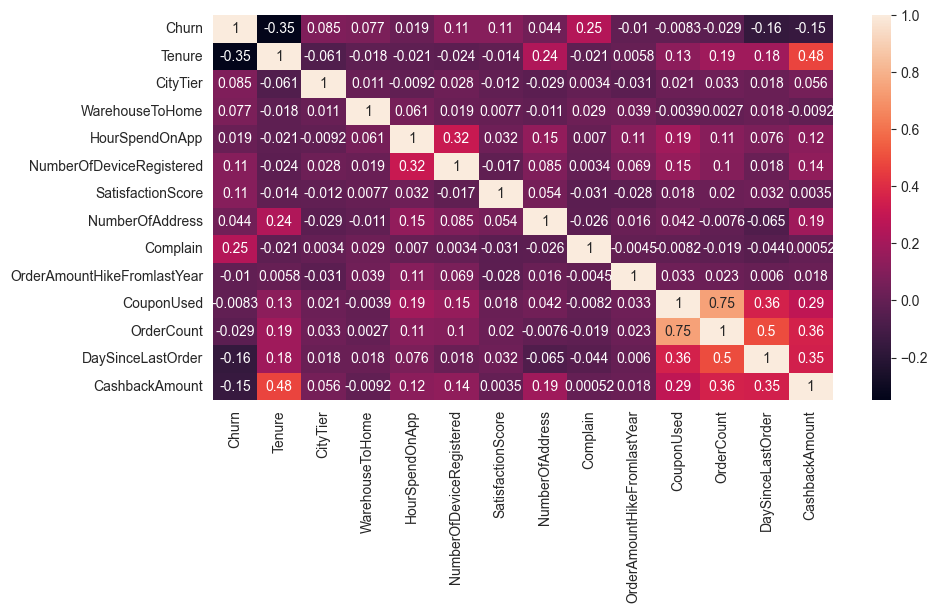

In [ ]:
plt.figure(figsize=(10,5))
sns.heatmap(corr, annot=True)
plt.show()

### Modelisation

 Splitting our data

In [ ]:
x=df.drop(columns=['CustomerID'])
train_df,test_df=train_test_split(df, test_size=0.2,stratify=df['Churn'], random_state=42)

id_train=train_df['CustomerID'].values
id_test=test_df['CustomerID'].values

X_train=train_df.drop(columns=['CustomerID','Churn'])
y_train=train_df['Churn']

X_test=test_df.drop(columns=['CustomerID','Churn'])
y_test=test_df['Churn']

skfcv=StratifiedKFold(n_splits=5,shuffle=True,random_state=42)

In [ ]:
cat_cols=['PreferredLoginDevice', 'PreferredPaymentMode', 'Gender',
       'PreferedOrderCat', 'MaritalStatus']

num_cols=['Tenure', 'CityTier', 'WarehouseToHome',
       'HourSpendOnApp', 'NumberOfDeviceRegistered', 'SatisfactionScore',
       'NumberOfAddress', 'Complain', 'OrderAmountHikeFromlastYear',
       'CouponUsed', 'OrderCount', 'DaySinceLastOrder', 'CashbackAmount',]

In [ ]:

num_pipeline=Pipeline([

    ("imputer",IterativeImputer(random_state=0)),
    ("scaler",StandardScaler())
])
cat_pipeline=Pipeline([
    ("one_encoder",OneHotEncoder(handle_unknown='ignore'))
])

preprocess=ColumnTransformer([
    ("num_preprocess",num_pipeline,num_cols),
    ("cat_preprocess",cat_pipeline,cat_cols)
])
model_log=Pipeline([
    ("preprocessor",preprocess),
    ("model",LogisticRegression(random_state=0))
])
#cross validate logistic regression model
print(f"Cross validation score for Logistic Regression: {np.mean(cross_val_score(model_log, X_train, y_train, cv=skfcv, scoring='f1'))}")

Cross validation score for Logistic Regression: 0.62782273028798


In [ ]:
model_log.fit(X_train, y_train)
print(f"Training accuracy score for Logistic Regression {accuracy_score(y_train, model_log.predict(X_train))}")
print(f"Testing accuracy score for Logistic Regression {accuracy_score(y_train, model_log.predict(X_train))}")
print(f"Training fscore for Logistic Regression: {f1_score(y_train, model_log.predict(X_train))}")
print(f"Testing fscore for Logistic Regression: {f1_score(y_test, model_log.predict(X_test))}")

Training accuracy score for Logistic Regression 0.8987566607460036
Testing accuracy score for Logistic Regression 0.8987566607460036
Training fscore for Logistic Regression: 0.645412130637636
Testing fscore for Logistic Regression: 0.6230529595015576


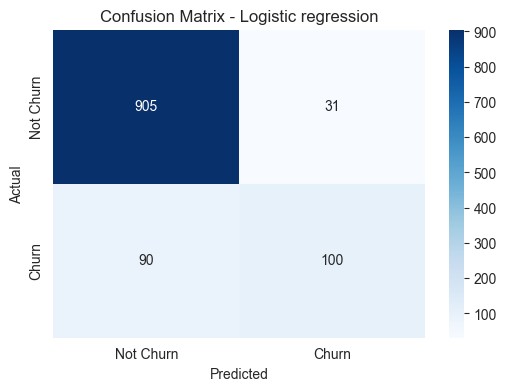

In [ ]:
cm_log = confusion_matrix(y_test, model_log.predict(X_test))

plt.figure(figsize=(6,4))
sns.heatmap(cm_log, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Not Churn', 'Churn'],
            yticklabels=['Not Churn', 'Churn'])

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Logistic regression")
plt.show()

In [ ]:
num_pipeline=Pipeline([
    ("imputer",IterativeImputer(random_state=0)),
    ("scaler",StandardScaler())
])
cat_pipeline=Pipeline([
    ("one_encoder",OneHotEncoder(handle_unknown='ignore'))
])

preprocess=ColumnTransformer([
    ("num_preprocess",num_pipeline,num_cols),
    ("cat_preprocess",cat_pipeline,cat_cols)
])
model_rf = Pipeline([
    ('prep', preprocess),
    ('rf', RandomForestClassifier(random_state=0)),
])
#cross validate logistic regression model
print(f"Cross validation scores for Random Forrest: {cross_val_score(model_rf, X_train, y_train, cv=skfcv, scoring='f1')}")
print(f"Cross validation average score for Random Forrest: {np.mean(cross_val_score(model_rf, X_train, y_train, cv=skfcv, scoring='f1'))}")

Cross validation scores for Random Forrest: [0.82481752 0.83088235 0.7734375  0.82527881 0.80442804]
Cross validation average score for Random Forrest: 0.8117688451757432


In [ ]:
model_rf.fit(X_train, y_train)
print(f"Training accuracy score for RandomForrest {accuracy_score(y_train,model_rf.predict(X_train))}")
print(f"Testing accuracy score for RandomForrest  {accuracy_score(y_test,model_rf.predict(X_test))}")
print(f"Training fscore for RandomForrest: {f1_score(y_train, model_rf.predict(X_train))}")
print(f"Testing fscore for RandomForrest: {f1_score(y_test, model_rf.predict(X_test))}")

Training accuracy score for RandomForrest 1.0
Testing accuracy score for RandomForrest  0.977797513321492
Training fscore for RandomForrest: 1.0
Testing fscore for RandomForrest: 0.9299719887955182


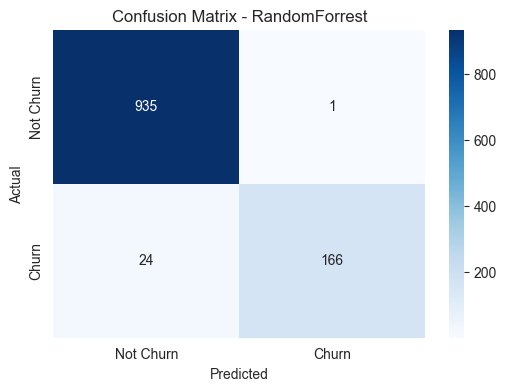

In [ ]:
cm_rf = confusion_matrix(y_test, model_rf.predict(X_test))

plt.figure(figsize=(6,4))
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Not Churn', 'Churn'],
            yticklabels=['Not Churn', 'Churn'])

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - RandomForrest")
plt.show()

In [ ]:
num_pipeline=Pipeline([
    ("imputer",IterativeImputer(random_state=0)),
    ("scaler",StandardScaler())
])
cat_pipeline=Pipeline([
    ("one_encoder",OneHotEncoder(handle_unknown='ignore'))
])

preprocessor=ColumnTransformer([
    ("num_preprocess",num_pipeline,num_cols),
    ("cat_preprocess",cat_pipeline,cat_cols)
])
model_xgb = Pipeline([
    ('prep', preprocess),
    ('xgb',XGBClassifier(verbosity=0,use_label_encoder=False))
])
#cross validate logistic regression model
print(f"Cross validation scores for XGB: {cross_val_score(model_xgb, X_train, y_train, cv=skfcv, scoring='f1')}")
print(f"Cross validation average score for XGB: {np.mean(cross_val_score(model_xgb, X_train, y_train, cv=skfcv, scoring='f1'))}")



Cross validation scores for XGB: [0.89041096 0.88194444 0.85611511 0.86524823 0.83985765]
Cross validation average score for XGB: 0.8667152778916257


In [ ]:
model_xgb.fit(X_train, y_train)
print(f"Training accuracy score for XGB {accuracy_score(y_train,model_xgb.predict(X_train))}")
print(f"Testing accuracy score for XGB  {accuracy_score(y_test,model_xgb.predict(X_test))}")
print(f"Training fscore for XGB: {f1_score(y_train, model_xgb.predict(X_train))}")
print(f"Testing fscore for XGB: {f1_score(y_test, model_xgb.predict(X_test))}")

Training accuracy score for XGB 1.0
Testing accuracy score for XGB  0.9893428063943162
Training fscore for XGB: 1.0
Testing fscore for XGB: 0.9680851063829787


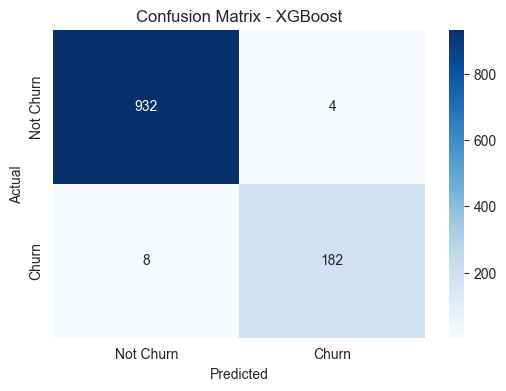

In [ ]:
cm_xgb = confusion_matrix(y_test, model_xgb.predict(X_test))

plt.figure(figsize=(6,4))
sns.heatmap(cm_xgb, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Not Churn', 'Churn'],
            yticklabels=['Not Churn', 'Churn'])

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - XGBoost")
plt.show()

In [ ]:
num_pipeline=Pipeline([
    ("imputer",IterativeImputer(random_state=0)),
    ("scaler",StandardScaler())
])
cat_pipeline=Pipeline([
    ("one_encoder",OneHotEncoder(handle_unknown='ignore'))
])

preprocessor=ColumnTransformer([
    ("num_preprocess",num_pipeline,num_cols),
    ("cat_preprocess",cat_pipeline,cat_cols)
])
model_lgbm = Pipeline([
    ('prep', preprocess),
    ('lgbm',LGBMClassifier(random_state=0))
])
#cross validate logistic regression model
print(f"Cross validation scores for LightGBM: {cross_val_score(model_lgbm, X_train, y_train, cv=skfcv, scoring='f1')}")
print(f"Cross validation average score for LightGBM: {np.mean(cross_val_score(model_lgbm, X_train, y_train, cv=skfcv, scoring='f1'))}")

[LightGBM] [Info] Number of positive: 607, number of negative: 2996
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001612 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 953
[LightGBM] [Info] Number of data points in the train set: 3603, number of used features: 34
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.168471 -> initscore=-1.596505
[LightGBM] [Info] Start training from score -1.596505


C:\Users\abdou\PycharmProjects\Ecommerce_churn_predcition\.venv\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Number of positive: 606, number of negative: 2997
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.013170 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 955
[LightGBM] [Info] Number of data points in the train set: 3603, number of used features: 34
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.168193 -> initscore=-1.598487
[LightGBM] [Info] Start training from score -1.598487


C:\Users\abdou\PycharmProjects\Ecommerce_churn_predcition\.venv\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Number of positive: 606, number of negative: 2997
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.002311 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 947
[LightGBM] [Info] Number of data points in the train set: 3603, number of used features: 34
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.168193 -> initscore=-1.598487
[LightGBM] [Info] Start training from score -1.598487


C:\Users\abdou\PycharmProjects\Ecommerce_churn_predcition\.venv\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Number of positive: 606, number of negative: 2997
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.019068 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 944
[LightGBM] [Info] Number of data points in the train set: 3603, number of used features: 34
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.168193 -> initscore=-1.598487
[LightGBM] [Info] Start training from score -1.598487


C:\Users\abdou\PycharmProjects\Ecommerce_churn_predcition\.venv\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Number of positive: 607, number of negative: 2997
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.004036 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 945
[LightGBM] [Info] Number of data points in the train set: 3604, number of used features: 34
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.168424 -> initscore=-1.596838
[LightGBM] [Info] Start training from score -1.596838


C:\Users\abdou\PycharmProjects\Ecommerce_churn_predcition\.venv\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Cross validation scores for LightGBM: [0.8641115  0.86006826 0.82352941 0.83274021 0.83571429]
[LightGBM] [Info] Number of positive: 607, number of negative: 2996
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.012027 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 953
[LightGBM] [Info] Number of data points in the train set: 3603, number of used features: 34
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.168471 -> initscore=-1.596505
[LightGBM] [Info] Start training from score -1.596505


C:\Users\abdou\PycharmProjects\Ecommerce_churn_predcition\.venv\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Number of positive: 606, number of negative: 2997
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.005843 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 955
[LightGBM] [Info] Number of data points in the train set: 3603, number of used features: 34
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.168193 -> initscore=-1.598487
[LightGBM] [Info] Start training from score -1.598487


C:\Users\abdou\PycharmProjects\Ecommerce_churn_predcition\.venv\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Number of positive: 606, number of negative: 2997
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000800 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 947
[LightGBM] [Info] Number of data points in the train set: 3603, number of used features: 34
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.168193 -> initscore=-1.598487
[LightGBM] [Info] Start training from score -1.598487


C:\Users\abdou\PycharmProjects\Ecommerce_churn_predcition\.venv\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Number of positive: 606, number of negative: 2997
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000912 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 944
[LightGBM] [Info] Number of data points in the train set: 3603, number of used features: 34
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.168193 -> initscore=-1.598487
[LightGBM] [Info] Start training from score -1.598487


C:\Users\abdou\PycharmProjects\Ecommerce_churn_predcition\.venv\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Number of positive: 607, number of negative: 2997
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000755 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 945
[LightGBM] [Info] Number of data points in the train set: 3604, number of used features: 34
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.168424 -> initscore=-1.596838
[LightGBM] [Info] Start training from score -1.596838
Cross validation average score for LightGBM: 0.8432327337291257


C:\Users\abdou\PycharmProjects\Ecommerce_churn_predcition\.venv\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


In [ ]:
model_lgbm.fit(X_train, y_train)
print(f"Training accuracy score for LightGBM {accuracy_score(y_train,model_lgbm.predict(X_train))}")
print(f"Testing accuracy score for LightGBM  {accuracy_score(y_test,model_lgbm.predict(X_test))}")
print(f"Training fscore for LightGBM: {f1_score(y_train, model_lgbm.predict(X_train))}")
print(f"Testing fscore for LightGBM: {f1_score(y_test, model_lgbm.predict(X_test))}")

[LightGBM] [Info] Number of positive: 758, number of negative: 3746
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000959 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1018
[LightGBM] [Info] Number of data points in the train set: 4504, number of used features: 34
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.168295 -> initscore=-1.597760
[LightGBM] [Info] Start training from score -1.597760
Training accuracy score for LightGBM 0.9984458259325044
Testing accuracy score for LightGBM  0.9849023090586145
Training fscore for LightGBM: 0.9953673064195897
Testing fscore for LightGBM: 0.9536784741144414


C:\Users\abdou\PycharmProjects\Ecommerce_churn_predcition\.venv\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\abdou\PycharmProjects\Ecommerce_churn_predcition\.venv\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\abdou\PycharmProjects\Ecommerce_churn_predcition\.venv\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\abdou\PycharmProjects\Ecommerce_churn_predcition\.venv\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


C:\Users\abdou\PycharmProjects\Ecommerce_churn_predcition\.venv\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


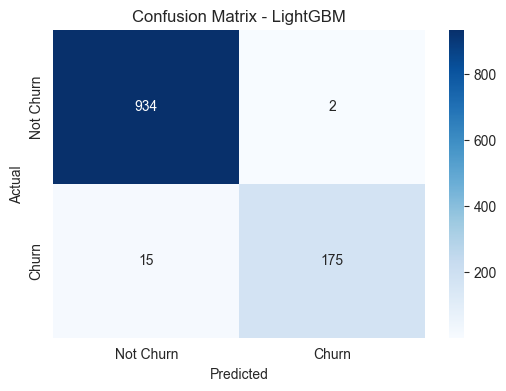

In [ ]:
cm_lgbm = confusion_matrix(y_test, model_lgbm.predict(X_test))

plt.figure(figsize=(6,4))
sns.heatmap(cm_lgbm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Not Churn', 'Churn'],
            yticklabels=['Not Churn', 'Churn'])

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - LightGBM")
plt.show()

In [ ]:


results = []

models = {
    "Logistic Regression": model_log,
    "Random Forest": model_rf,
    "XGBoost": model_xgb,
    "LightGBM": model_lgbm
}

for name, model in models.items():
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    results.append({
        "Model": name,
        "CV Average F1": np.mean(cross_val_score(model, X_train, y_train, cv=skfcv, scoring="f1")),
        "Train Acc": accuracy_score(y_train, train_pred),
        "Test Acc": accuracy_score(y_test, test_pred),
        "Train F1": f1_score(y_train, train_pred),
        "Test F1": f1_score(y_test, test_pred)
    })



C:\Users\abdou\PycharmProjects\Ecommerce_churn_predcition\.venv\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\abdou\PycharmProjects\Ecommerce_churn_predcition\.venv\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Number of positive: 607, number of negative: 2996
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000658 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 953
[LightGBM] [Info] Number of data points in the train set: 3603, number of used features: 34
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.168471 -> initscore=-1.596505
[LightGBM] [Info] Start training from score -1.596505


C:\Users\abdou\PycharmProjects\Ecommerce_churn_predcition\.venv\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Number of positive: 606, number of negative: 2997
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000697 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 955
[LightGBM] [Info] Number of data points in the train set: 3603, number of used features: 34
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.168193 -> initscore=-1.598487
[LightGBM] [Info] Start training from score -1.598487


C:\Users\abdou\PycharmProjects\Ecommerce_churn_predcition\.venv\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Number of positive: 606, number of negative: 2997
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000744 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 947
[LightGBM] [Info] Number of data points in the train set: 3603, number of used features: 34
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.168193 -> initscore=-1.598487
[LightGBM] [Info] Start training from score -1.598487


C:\Users\abdou\PycharmProjects\Ecommerce_churn_predcition\.venv\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Number of positive: 606, number of negative: 2997
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000738 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 944
[LightGBM] [Info] Number of data points in the train set: 3603, number of used features: 34
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.168193 -> initscore=-1.598487
[LightGBM] [Info] Start training from score -1.598487


C:\Users\abdou\PycharmProjects\Ecommerce_churn_predcition\.venv\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Number of positive: 607, number of negative: 2997
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000231 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 945
[LightGBM] [Info] Number of data points in the train set: 3604, number of used features: 34
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.168424 -> initscore=-1.596838
[LightGBM] [Info] Start training from score -1.596838


C:\Users\abdou\PycharmProjects\Ecommerce_churn_predcition\.venv\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


In [ ]:
df_results = pd.DataFrame(results)
df_results.head()

,Model,CV Average F1,Train Acc,Test Acc,Train F1,Test F1
0,Logistic Regression,0.627823,0.898757,0.892540,0.645412,0.623053
1,Random Forest,0.811769,1.000000,0.977798,1.000000,0.929972
2,XGBoost,0.866715,1.000000,0.989343,1.000000,0.968085
3,LightGBM,0.843233,0.998446,0.984902,0.995367,0.953678


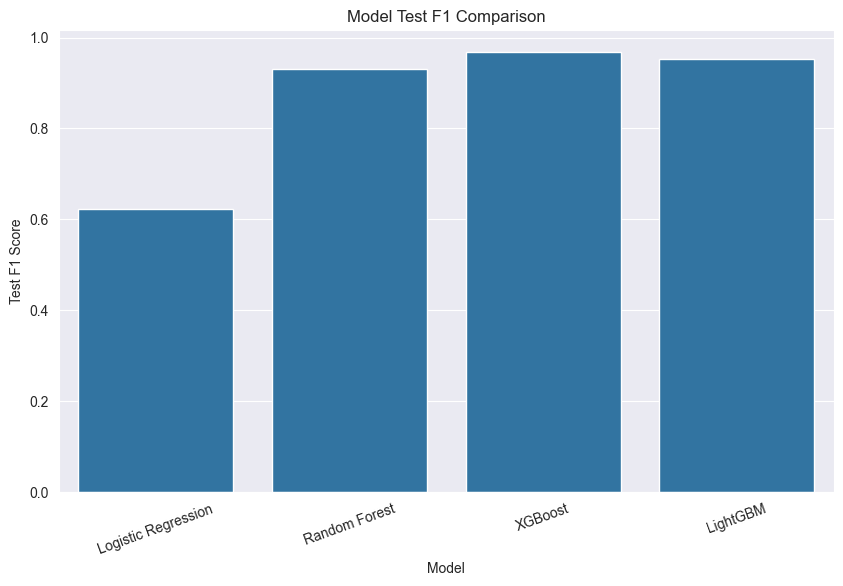

In [ ]:

plt.figure(figsize=(10,6))
sns.barplot(data=df_results, x="Model", y="Test F1")
plt.title("Model Test F1 Comparison")
plt.ylabel("Test F1 Score")
plt.xticks(rotation=20)
plt.show()


C:\Users\abdou\PycharmProjects\Ecommerce_churn_predcition\.venv\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


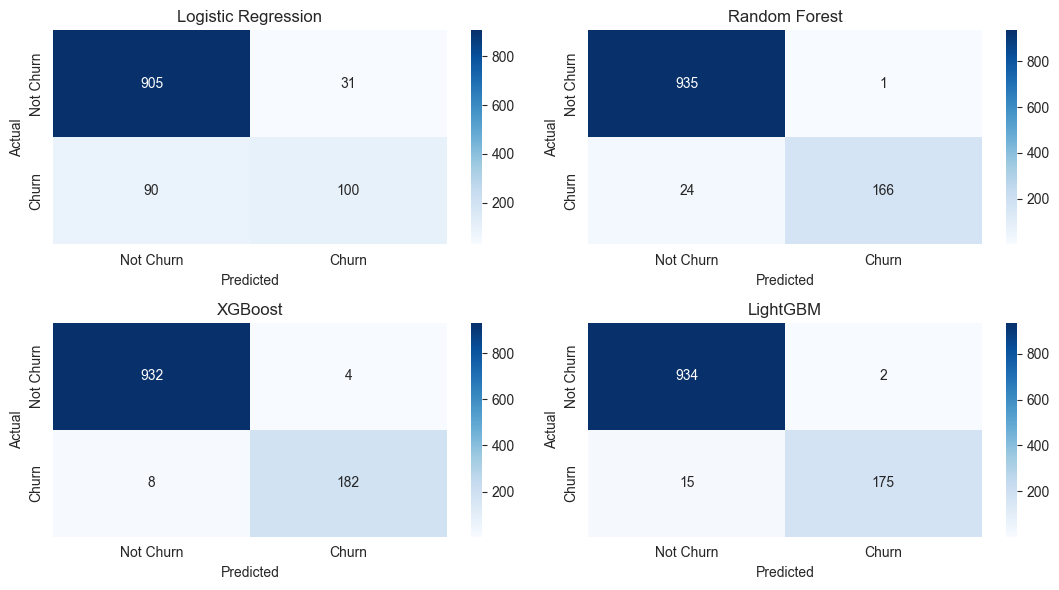

In [ ]:

# Calcul des matrices de confusion
cm_lr = confusion_matrix(y_test, model_log.predict(X_test))
cm_rf = confusion_matrix(y_test, model_rf.predict(X_test))
cm_xgb = confusion_matrix(y_test, model_xgb.predict(X_test))
cm_lgbm = confusion_matrix(y_test, model_lgbm.predict(X_test))

# Création de la figure avec 4 sous-plots
fig, axes = plt.subplots(2, 2, figsize=(11, 6))

models_cm = [
    (cm_lr, "Logistic Regression"),
    (cm_rf, "Random Forest"),
    (cm_xgb, "XGBoost"),
    (cm_lgbm, "LightGBM")
]

# Boucle pour afficher chaque matrice
for ax, (cm, title) in zip(axes.flatten(), models_cm):
    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=['Not Churn', 'Churn'],
        yticklabels=['Not Churn', 'Churn'],
        ax=ax
    )
    ax.set_title(title)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()


### Interpretation of results with SHAP

In [ ]:
preprocess = model_xgb.named_steps["prep"]
xgb_model = model_xgb.named_steps["xgb"]
X_transformed=preprocess.transform(x)
explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_transformed)
feature_names = model_xgb.named_steps["prep"].get_feature_names_out()

print(len(X_transformed))



5630


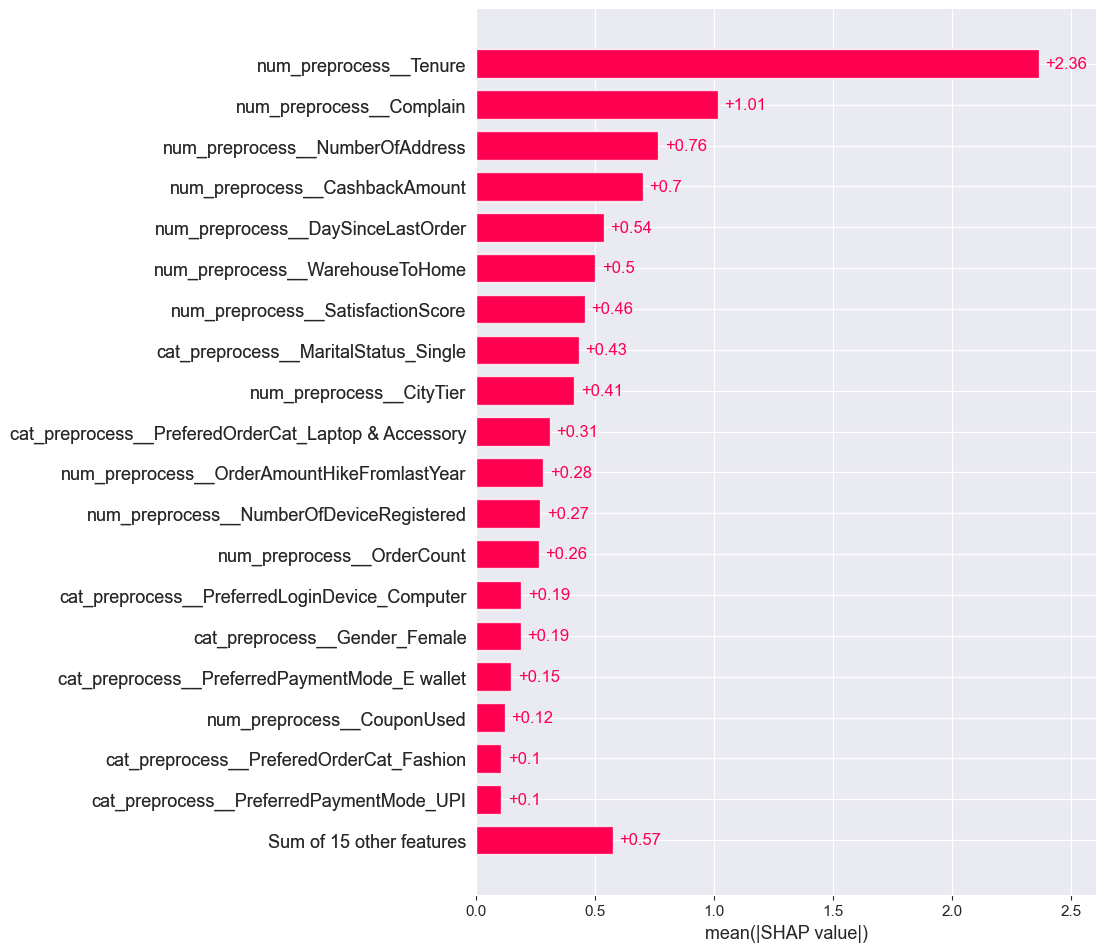

In [ ]:
shap_exp = shap.Explanation(
    values = shap_values,
    base_values = explainer.expected_value,
    data = X_transformed,
    feature_names = feature_names
)
shap.plots.bar(shap_exp,max_display=20,)


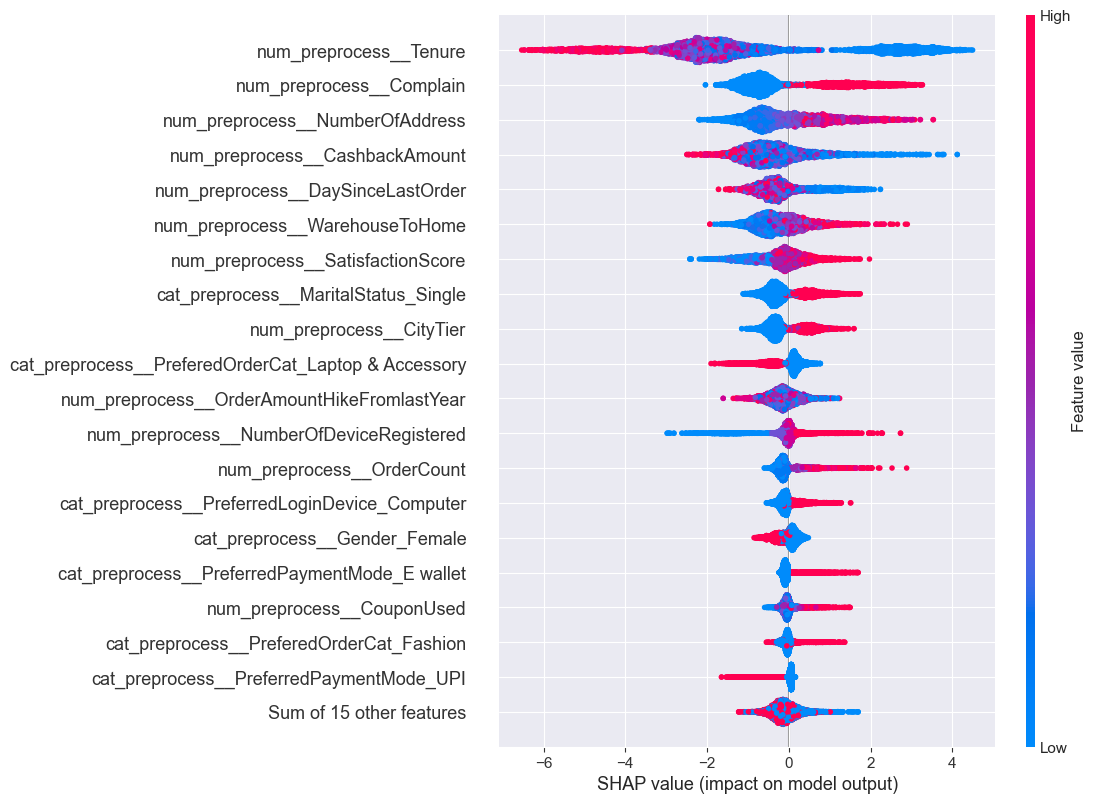

In [ ]:
shap.plots.beeswarm(shap_exp,max_display=20)

In [ ]:
i=814
exp_nochurn = shap.Explanation(
    values = shap_values[i],
    base_values = explainer.expected_value,
    data = X_transformed[i],
    feature_names = feature_names
)
i=800
exp_churn = shap.Explanation(
    values = shap_values[i],
    base_values = explainer.expected_value,
    data = X_transformed[i],
    feature_names = feature_names
)
# Show force plot


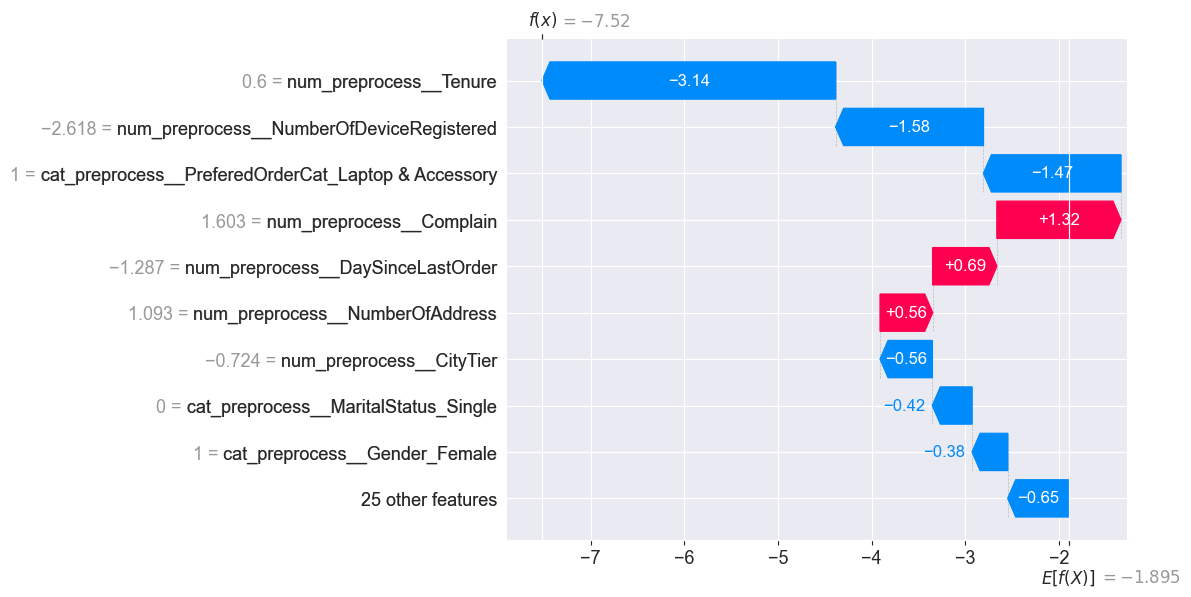

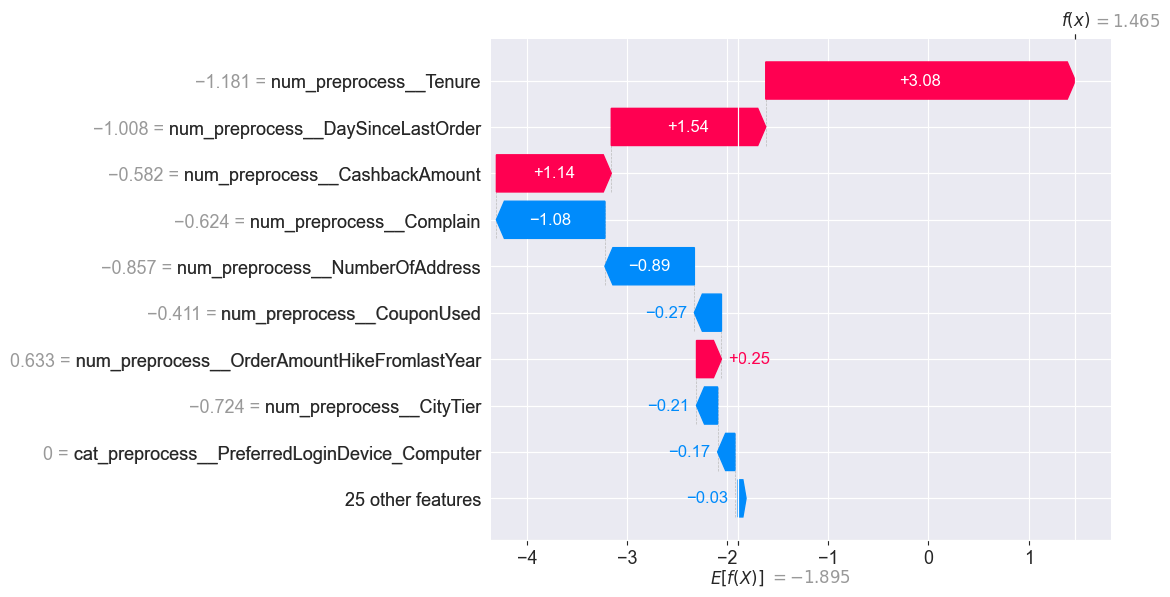

In [ ]:
shap.plots.waterfall(exp_churn, max_display=10)
shap.plots.waterfall(exp_nochurn, max_display=10)


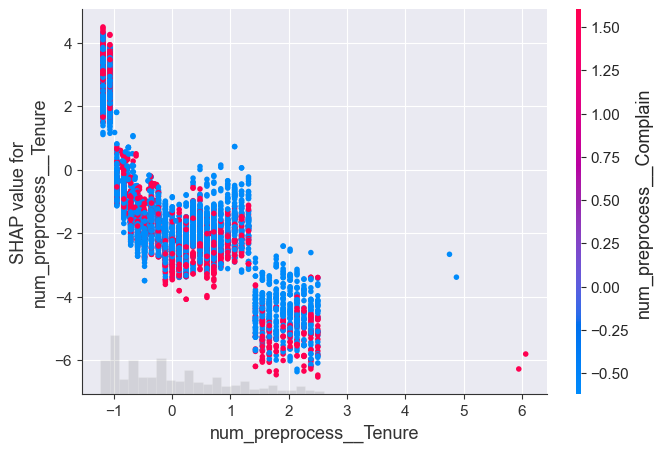

In [ ]:
shap.plots.scatter(shap_exp[:,"num_preprocess__Tenure"],color=shap_exp[:,"num_preprocess__Complain"])

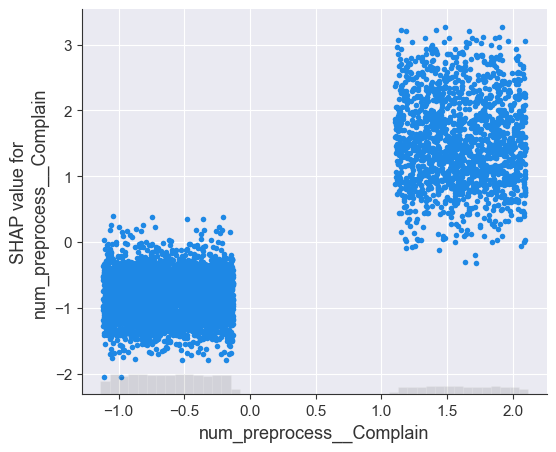

In [ ]:
shap.plots.scatter(shap_exp[:,"num_preprocess__Complain"])

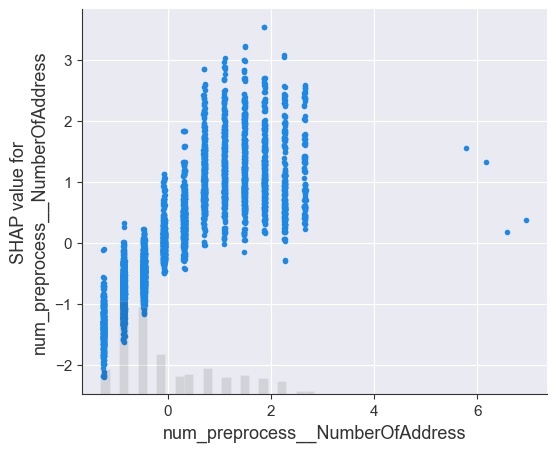

In [ ]:
shap.plots.scatter(shap_exp[:,"num_preprocess__NumberOfAddress"])

In [ ]:

y_proba = model_xgb.predict_proba(x)[:, 1]

# 2. Compute risk segment
def risk_segment(p):
    if p < 0.3:
        return "low"
    elif p < 0.7:
        return "medium"
    else:
        return "high"


In [ ]:
# 3. Extract top drivers from SHAP values
def top_drivers(shap_row, feature_names, n=5):
    idx = np.argsort(np.abs(shap_row.values))[-n:][::-1]

    clean_list = []
    for i in idx:
        raw = feature_names[i]
        clean = raw.split("__")[-1]
        clean_list.append((clean, shap_row.values[i]))

    return clean_list


In [ ]:
# 4. Build a clean result dataframe
results = pd.DataFrame({
    "customer_id": df['CustomerID'],
    "probability": y_proba,
})

# 5. Assign risk segment
results["risk_segment"] = results["probability"].apply(risk_segment)

In [ ]:
# 6. Add top drivers per customer
results["top_drivers"] = [
    top_drivers(shap_exp[i], shap_exp.feature_names)
    for i in range(len(shap_exp))
]

In [ ]:
actions = {
    "Tenure": {
        "positive": [
            "Mettre en avant les avantages liés à l'ancienneté, proposer un programme VIP fidélité et envoyer un message de remerciement personnalisé."
        ],
        "negative": [
            "Analyser pourquoi un client ancien devient insatisfait et offrir un geste commercial pour éviter son départ."
        ]
    },

    "Complain": {
        "positive": [
            "Communiquer que les plaintes ont été prises en compte, proposer un suivi satisfaction post-résolution et envoyer une offre compensatrice."
        ],
        "negative": [
            "Déclencher une intervention proactive du support, appeler le client pour résoudre ses problèmes urgents et proposer une compensation immédiate."
        ]
    },

    "NumberOfAddress": {
        "positive": [
            "Proposer un service premium multi-adresses et envoyer des recommandations selon les adresses fréquentes."
        ],
        "negative": [
            "Vérifier une éventuelle instabilité logistique, proposer une option de livraison prioritaire et assurer une meilleure précision de localisation."
        ]
    },

    "CashbackAmount": {
        "positive": [
            "Renforcer les offres cashback car elles fonctionnent et envoyer des récompenses supplémentaires."
        ],
        "negative": [
            "Introduire un plan de cashback plus attractif et envoyer des coupons personnalisés."
        ]
    },

    "DaySinceLastOrder": {
        "positive": [
            "Étant donné que le client a commandé récemment, envoyer des offres pertinentes et proposer un programme fidélité pour maintenir l’engagement."
        ],
        "negative": [
            "Lancer une campagne de ré-engagement, proposer une promotion limitée dans le temps et envoyer un rappel automatisé."
        ]
    },

    "WarehouseToHome": {
        "positive": [
            "Mettre en avant la rapidité de livraison actuelle."
        ],
        "negative": [
            "Proposer une option livraison express, réduire l'estimation de délai et optimiser la logistique locale."
        ]
    },

    "SatisfactionScore": {
        "positive": [
            "Encourager l'évaluation positive et proposer un bonus fidélité pour maintenir la satisfaction."
        ],
        "negative": [
            "Demander un feedback détaillé, offrir un bon de réduction pour compenser l'insatisfaction et proposer une assistance prioritaire."
        ]
    },

    "CityTier": {
        "positive": [
            "Envoyer des offres adaptées au niveau de la ville."
        ],
        "negative": [
            "Adapter les promotions au pouvoir d'achat local et améliorer la disponibilité des produits dans la zone."
        ]
    },

    "OrderAmountHikeFromlastYear": {
        "positive": [
            "Remercier le client pour sa hausse de dépenses, proposer un bonus fidélité et envoyer une offre VIP."
        ],
        "negative": [
            "Analyser pourquoi les dépenses baissent, envoyer une offre de relance incitative et proposer une remise personnalisée."
        ]
    },

    "OrderCount": {
        "positive": [
            "Récompenser les commandes fréquentes et proposer un palier supplémentaire de points fidélité."
        ],
        "negative": [
            "Envoyer une campagne incitative de retour et proposer une remise pour réactiver l’activité."
        ]
    },

    "NumberOfDeviceRegistered": {
        "positive": [
            "Promouvoir les avantages multi-plateformes."
        ],
        "negative": [
            "Encourager l’utilisation multi-device et proposer une synchronisation améliorée."
        ]
    },

    "PreferredOrderCat_Laptop & Accessory": {
        "positive": [
            "Envoyer des recommandations tech personnalisées."
        ],
        "negative": [
            "Offrir des réductions sur les accessoires populaires et proposer des bundles d'achat."
        ]
    },

    "PreferredOrderCat_Fashion": {
        "positive": [
            "Proposer du contenu mode personnalisé."
        ],
        "negative": [
            "Offrir des offres mode ciblées."
        ]
    },

    "PreferredPaymentMode_E wallet": {
        "positive": [
            "Proposer un cashback spécial e-wallet."
        ],
        "negative": [
            "Introduire des avantages exclusifs pour e-wallet."
        ]
    },

    "PreferredPaymentMode_UPI": {
        "positive": [
            "Envoyer des promotions UPI dédiées."
        ],
        "negative": [
            "Proposer un cashback UPI attractif."
        ]
    },

    "CouponUsed": {
        "positive": [
            "Continuer à envoyer des coupons puisque cela fonctionne."
        ],
        "negative": [
            "Proposer des coupons plus incitatifs et envoyer une offre personnalisée basée sur ses achats."
        ]
    }
}


In [ ]:
# 4. Function generating recommendations based on SHAP sign
def recommend_actions(top_driver_list, action_map):
    recs = []
    for feature, importance in top_driver_list:
        if feature in action_map:
            if importance > 0:
                recs.extend(action_map[feature]["negative"])
            else:
                recs.extend(action_map[feature]["positive"])
    return recs[:3]


In [ ]:

results["solutions"] = results["top_drivers"].apply(
    lambda drivers: recommend_actions(drivers, actions)
)

In [ ]:
results.head()

,customer_id,probability,risk_segment,top_drivers,solutions
0,50001,0.938431,high,"[(NumberOfAddress, 2.5844214), (Complain, 2.28...",[Vérifier une éventuelle instabilité logistiqu...
1,50002,0.995489,high,"[(Complain, 2.7932386), (CashbackAmount, 1.923...",[Déclencher une intervention proactive du supp...
2,50003,0.994601,high,"[(CashbackAmount, 2.399289), (Complain, 2.2600...",[Introduire un plan de cashback plus attractif...
3,50004,0.994103,high,"[(Tenure, 3.519967), (NumberOfAddress, 2.30863...",[Analyser pourquoi un client ancien devient in...
4,50005,0.894133,high,"[(Tenure, 3.4718165), (SatisfactionScore, 1.26...",[Analyser pourquoi un client ancien devient in...


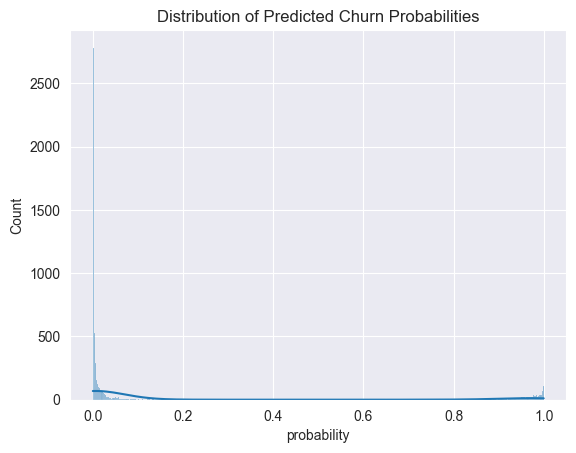

In [ ]:
sns.histplot(results["probability"], kde=True)
plt.title("Distribution of Predicted Churn Probabilities")
plt.show()

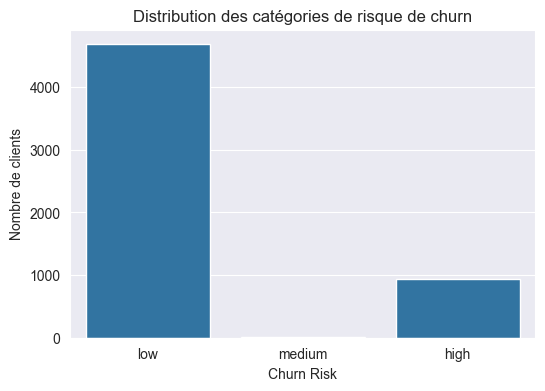

In [ ]:


plt.figure(figsize=(6,4))
sns.countplot(data=results, x="risk_segment", order=["low","medium","high"])
plt.title("Distribution des catégories de risque de churn")
plt.xlabel("Churn Risk")
plt.ylabel("Nombre de clients")
plt.show()


In [ ]:
import joblib

# Save model with protocol 4 to avoid numpy random state issues
joblib.dump(model_xgb, 'churn_model.pkl', protocol=4)
print("✅ Model saved as 'churn_model.pkl'")

# Save feature info
feature_info = {
    'cat_cols': cat_cols,
    'num_cols': num_cols,
    'all_features': list(x.columns)
}
joblib.dump(feature_info, 'feature_info.pkl')
print("✅ Feature info saved as 'feature_info.pkl'")

✅ Model saved as 'churn_model.pkl'
✅ Feature info saved as 'feature_info.pkl'


### Hyperparameter tuning

In [ ]:
def objective_xgb(trial):
    params = {
    "max_depth": trial.suggest_int("max_depth", 3, 15),
    "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.1),
    "n_estimators": trial.suggest_int("n_estimators", 100, 1000),
    "subsample": trial.suggest_float("subsample", 0.5, 1),
    "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1),
    "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
    "gamma": trial.suggest_float("gamma", 0, 5),
    "lambda": trial.suggest_float("lambda", 0, 5),
    "alpha": trial.suggest_float("alpha", 0, 5),
}

    model_xgb_tun = Pipeline([
        ("preprocess", preprocess),
        ("model", XGBClassifier(**params, device='cuda'))
    ])

    score = np.mean(cross_val_score(model_xgb_tun, X_train, y_train, cv=skfcv, scoring='f1'))
    return score

In [ ]:
study = optuna.create_study(study_name="xgboost_study_cuda", direction="maximize")
study.optimize(objective_xgb, n_trials=250, show_progress_bar=True, n_jobs=-1)

# Retrieve the best parameter values
best_params = study.best_params
print(f"\nBest parameters: {best_params}")

[I 2025-12-06 10:42:00,878] A new study created in memory with name: xgboost_study_cuda
Best trial: 4. Best value: 0.654969:   0%|          | 1/250 [00:30<2:04:57, 30.11s/it]

[I 2025-12-06 10:42:30,929] Trial 4 finished with value: 0.6549691911735425 and parameters: {'max_depth': 13, 'learning_rate': 0.08221004096491494, 'n_estimators': 111, 'subsample': 0.5366112718524757, 'colsample_bytree': 0.6674744944596049, 'min_child_weight': 1, 'gamma': 3.061498912020411, 'lambda': 1.8062365637063609, 'alpha': 4.970269423052655}. Best is trial 4 with value: 0.6549691911735425.


Best trial: 6. Best value: 0.696162:   1%|          | 2/250 [00:48<1:36:35, 23.37s/it]

[I 2025-12-06 10:42:49,625] Trial 6 finished with value: 0.6961618872996758 and parameters: {'max_depth': 6, 'learning_rate': 0.0661582246146677, 'n_estimators': 166, 'subsample': 0.7641459958298822, 'colsample_bytree': 0.5237563003226798, 'min_child_weight': 1, 'gamma': 2.3560970992992916, 'lambda': 3.946765545753739, 'alpha': 2.0161806542675915}. Best is trial 6 with value: 0.6961618872996758.


Best trial: 2. Best value: 0.709128:   1%|          | 3/250 [01:12<1:37:33, 23.70s/it]

[I 2025-12-06 10:43:13,719] Trial 2 finished with value: 0.7091277198129791 and parameters: {'max_depth': 10, 'learning_rate': 0.08821064702610579, 'n_estimators': 330, 'subsample': 0.6957137319325836, 'colsample_bytree': 0.9458113925760288, 'min_child_weight': 9, 'gamma': 2.2816649388444175, 'lambda': 4.5794271444130965, 'alpha': 1.062766178180699}. Best is trial 2 with value: 0.7091277198129791.


Best trial: 3. Best value: 0.731895:   2%|▏         | 4/250 [01:17<1:06:57, 16.33s/it]

[I 2025-12-06 10:43:18,726] Trial 3 finished with value: 0.731895041295432 and parameters: {'max_depth': 5, 'learning_rate': 0.03151572948394972, 'n_estimators': 335, 'subsample': 0.834896353821653, 'colsample_bytree': 0.6359582979673093, 'min_child_weight': 6, 'gamma': 1.9047448446604283, 'lambda': 1.526636339843079, 'alpha': 0.18512084233711923}. Best is trial 3 with value: 0.731895041295432.


Best trial: 3. Best value: 0.731895:   2%|▏         | 5/250 [01:34<1:07:29, 16.53s/it]

[I 2025-12-06 10:43:35,635] Trial 5 finished with value: 0.7033149583319812 and parameters: {'max_depth': 15, 'learning_rate': 0.07442174143687458, 'n_estimators': 430, 'subsample': 0.6665886757916402, 'colsample_bytree': 0.7152004683810952, 'min_child_weight': 2, 'gamma': 4.189983855342694, 'lambda': 1.9379634504588976, 'alpha': 1.1698772524398708}. Best is trial 3 with value: 0.731895041295432.


Best trial: 3. Best value: 0.731895:   2%|▏         | 6/250 [01:35<45:22, 11.16s/it]  

[I 2025-12-06 10:43:36,360] Trial 0 finished with value: 0.6792076526611586 and parameters: {'max_depth': 6, 'learning_rate': 0.0342086891630123, 'n_estimators': 450, 'subsample': 0.9271388078648652, 'colsample_bytree': 0.525657562300558, 'min_child_weight': 9, 'gamma': 4.3974050792238755, 'lambda': 4.558503842326474, 'alpha': 0.8439422683155767}. Best is trial 3 with value: 0.731895041295432.


Best trial: 3. Best value: 0.731895:   3%|▎         | 7/250 [01:55<57:32, 14.21s/it]

[I 2025-12-06 10:43:56,854] Trial 10 finished with value: 0.6763725361462483 and parameters: {'max_depth': 14, 'learning_rate': 0.05556119609849457, 'n_estimators': 211, 'subsample': 0.739857215886554, 'colsample_bytree': 0.9262908119882992, 'min_child_weight': 4, 'gamma': 4.495209214578778, 'lambda': 0.5803182688513314, 'alpha': 3.2536699753054483}. Best is trial 3 with value: 0.731895041295432.


Best trial: 3. Best value: 0.731895:   3%|▎         | 8/250 [02:04<50:09, 12.43s/it]

[I 2025-12-06 10:44:05,479] Trial 7 finished with value: 0.6900802961394232 and parameters: {'max_depth': 13, 'learning_rate': 0.019354577949180322, 'n_estimators': 542, 'subsample': 0.5395846685240029, 'colsample_bytree': 0.580081625564312, 'min_child_weight': 5, 'gamma': 3.1255281995661246, 'lambda': 3.930433877045499, 'alpha': 0.2386982018860695}. Best is trial 3 with value: 0.731895041295432.


Best trial: 3. Best value: 0.731895:   4%|▎         | 9/250 [02:17<50:31, 12.58s/it]

[I 2025-12-06 10:44:18,384] Trial 1 finished with value: 0.7125609397112667 and parameters: {'max_depth': 12, 'learning_rate': 0.08047954881796612, 'n_estimators': 793, 'subsample': 0.5343100846626776, 'colsample_bytree': 0.6394646127543608, 'min_child_weight': 4, 'gamma': 3.696246997603376, 'lambda': 2.7576047614545702, 'alpha': 0.043475138372496835}. Best is trial 3 with value: 0.731895041295432.


Best trial: 3. Best value: 0.731895:   4%|▍         | 10/250 [02:20<38:49,  9.71s/it]

[I 2025-12-06 10:44:21,665] Trial 9 finished with value: 0.6850883994967167 and parameters: {'max_depth': 7, 'learning_rate': 0.028916821239769692, 'n_estimators': 441, 'subsample': 0.7241727466687762, 'colsample_bytree': 0.7785237256970831, 'min_child_weight': 1, 'gamma': 3.0084999549902824, 'lambda': 0.8954431974524829, 'alpha': 4.226943066045901}. Best is trial 3 with value: 0.731895041295432.


Best trial: 8. Best value: 0.754452:   4%|▍         | 11/250 [02:23<30:34,  7.67s/it]

[I 2025-12-06 10:44:24,703] Trial 8 finished with value: 0.7544517468683688 and parameters: {'max_depth': 8, 'learning_rate': 0.02929532039017315, 'n_estimators': 325, 'subsample': 0.685378190249006, 'colsample_bytree': 0.6663202074508588, 'min_child_weight': 3, 'gamma': 0.8382469866721959, 'lambda': 1.17435955628851, 'alpha': 1.3113449261396737}. Best is trial 8 with value: 0.7544517468683688.


Best trial: 8. Best value: 0.754452:   5%|▍         | 12/250 [02:58<1:02:43, 15.81s/it]

[I 2025-12-06 10:44:59,138] Trial 13 finished with value: 0.7117054654788293 and parameters: {'max_depth': 5, 'learning_rate': 0.04159298461516116, 'n_estimators': 350, 'subsample': 0.8261493296453617, 'colsample_bytree': 0.9469811130250634, 'min_child_weight': 8, 'gamma': 1.4036962371542916, 'lambda': 3.5795493938964977, 'alpha': 2.8118423049982737}. Best is trial 8 with value: 0.7544517468683688.


Best trial: 8. Best value: 0.754452:   5%|▌         | 13/250 [03:05<51:49, 13.12s/it]  

[I 2025-12-06 10:45:06,077] Trial 14 finished with value: 0.6971901100158686 and parameters: {'max_depth': 9, 'learning_rate': 0.04459708052987339, 'n_estimators': 223, 'subsample': 0.5432394958332245, 'colsample_bytree': 0.5637728592305754, 'min_child_weight': 8, 'gamma': 0.7276558492177149, 'lambda': 4.337248895136505, 'alpha': 1.8575868709431815}. Best is trial 8 with value: 0.7544517468683688.


Best trial: 8. Best value: 0.754452:   6%|▌         | 14/250 [03:09<40:33, 10.31s/it]

[I 2025-12-06 10:45:09,900] Trial 11 finished with value: 0.669046070614578 and parameters: {'max_depth': 3, 'learning_rate': 0.07916134156853143, 'n_estimators': 784, 'subsample': 0.778655729376614, 'colsample_bytree': 0.9764345078892729, 'min_child_weight': 6, 'gamma': 4.057891757851563, 'lambda': 2.6655281391022214, 'alpha': 3.113450427714745}. Best is trial 8 with value: 0.7544517468683688.


Best trial: 8. Best value: 0.754452:   6%|▌         | 15/250 [04:00<1:28:47, 22.67s/it]

[I 2025-12-06 10:46:01,207] Trial 16 finished with value: 0.669373792262409 and parameters: {'max_depth': 12, 'learning_rate': 0.09867148080484979, 'n_estimators': 600, 'subsample': 0.5596941216495552, 'colsample_bytree': 0.5952075540815325, 'min_child_weight': 6, 'gamma': 4.075251364376565, 'lambda': 4.053880276922303, 'alpha': 3.8831295028136}. Best is trial 8 with value: 0.7544517468683688.


Best trial: 8. Best value: 0.754452:   6%|▋         | 16/250 [04:24<1:30:00, 23.08s/it]

[I 2025-12-06 10:46:25,232] Trial 12 finished with value: 0.7335328170827748 and parameters: {'max_depth': 8, 'learning_rate': 0.07157188445964198, 'n_estimators': 680, 'subsample': 0.6616959411191573, 'colsample_bytree': 0.7410042292845715, 'min_child_weight': 6, 'gamma': 0.9142691379693058, 'lambda': 3.1829600890958663, 'alpha': 2.4536150476771503}. Best is trial 8 with value: 0.7544517468683688.


Best trial: 8. Best value: 0.754452:   7%|▋         | 17/250 [04:33<1:12:59, 18.80s/it]

[I 2025-12-06 10:46:34,078] Trial 17 finished with value: 0.7097152581440723 and parameters: {'max_depth': 3, 'learning_rate': 0.04404850535493712, 'n_estimators': 754, 'subsample': 0.9620103249462292, 'colsample_bytree': 0.8241405328935885, 'min_child_weight': 7, 'gamma': 0.7591088938253832, 'lambda': 0.0059317425432565685, 'alpha': 2.502997908695296}. Best is trial 8 with value: 0.7544517468683688.


Best trial: 8. Best value: 0.754452:   7%|▋         | 18/250 [04:41<1:00:52, 15.74s/it]

[I 2025-12-06 10:46:42,710] Trial 18 finished with value: 0.7141790728757056 and parameters: {'max_depth': 3, 'learning_rate': 0.04093422254849525, 'n_estimators': 765, 'subsample': 0.8692450526853281, 'colsample_bytree': 0.815812923641505, 'min_child_weight': 7, 'gamma': 0.7722891100384799, 'lambda': 0.06907080530527865, 'alpha': 2.312221437189247}. Best is trial 8 with value: 0.7544517468683688.


Best trial: 8. Best value: 0.754452:   8%|▊         | 19/250 [04:52<54:58, 14.28s/it]  

[I 2025-12-06 10:46:53,582] Trial 15 finished with value: 0.7325034844569728 and parameters: {'max_depth': 11, 'learning_rate': 0.0424112423309575, 'n_estimators': 858, 'subsample': 0.6195193653892284, 'colsample_bytree': 0.6504363242958733, 'min_child_weight': 5, 'gamma': 1.480315182992264, 'lambda': 1.620696329382802, 'alpha': 1.1301989580574041}. Best is trial 8 with value: 0.7544517468683688.


Best trial: 8. Best value: 0.754452:   8%|▊         | 20/250 [05:03<50:45, 13.24s/it]

[I 2025-12-06 10:47:04,402] Trial 19 finished with value: 0.6943657944746418 and parameters: {'max_depth': 3, 'learning_rate': 0.014104258640065596, 'n_estimators': 671, 'subsample': 0.8981564853307694, 'colsample_bytree': 0.7947346194963776, 'min_child_weight': 7, 'gamma': 0.3556811628744123, 'lambda': 0.0161770889148114, 'alpha': 1.765270264227604}. Best is trial 8 with value: 0.7544517468683688.


Best trial: 8. Best value: 0.754452:   8%|▊         | 21/250 [05:13<46:24, 12.16s/it]

[I 2025-12-06 10:47:14,048] Trial 20 finished with value: 0.685943179810318 and parameters: {'max_depth': 3, 'learning_rate': 0.010493810778837192, 'n_estimators': 755, 'subsample': 0.8949489636671522, 'colsample_bytree': 0.7996537013210758, 'min_child_weight': 6, 'gamma': 0.14119754662596407, 'lambda': 0.07793522212068904, 'alpha': 1.6889898666377687}. Best is trial 8 with value: 0.7544517468683688.


Best trial: 8. Best value: 0.754452:   9%|▉         | 22/250 [05:25<45:59, 12.10s/it]

[I 2025-12-06 10:47:26,016] Trial 22 finished with value: 0.6763529350449715 and parameters: {'max_depth': 3, 'learning_rate': 0.010510667214467945, 'n_estimators': 670, 'subsample': 0.8790634525395589, 'colsample_bytree': 0.7921273788281011, 'min_child_weight': 3, 'gamma': 0.5264037875533327, 'lambda': 1.1778194088325236, 'alpha': 1.7236533206904485}. Best is trial 8 with value: 0.7544517468683688.


Best trial: 21. Best value: 0.785735:   9%|▉         | 23/250 [05:52<1:03:01, 16.66s/it]

[I 2025-12-06 10:47:53,307] Trial 21 finished with value: 0.7857349071011662 and parameters: {'max_depth': 9, 'learning_rate': 0.010001052908247113, 'n_estimators': 991, 'subsample': 0.900210654404629, 'colsample_bytree': 0.8133631556218339, 'min_child_weight': 6, 'gamma': 0.186453612437824, 'lambda': 0.07560188014283442, 'alpha': 1.6973515422999412}. Best is trial 21 with value: 0.7857349071011662.


Best trial: 23. Best value: 0.801022:  10%|▉         | 24/250 [05:54<55:36, 14.76s/it]  


[I 2025-12-06 10:47:55,141] Trial 23 finished with value: 0.8010221212262625 and parameters: {'max_depth': 9, 'learning_rate': 0.058858442601107896, 'n_estimators': 669, 'subsample': 0.6191528347944741, 'colsample_bytree': 0.8140728880784667, 'min_child_weight': 3, 'gamma': 0.2129722458562986, 'lambda': 3.1543511164339195, 'alpha': 2.047306665240564}. Best is trial 23 with value: 0.8010221212262625.


KeyboardInterrupt: 

In [ ]:
def objective_lgbm(trial):
    params = {
    "num_leaves": trial.suggest_int("num_leaves", 16, 128),
    "max_depth": trial.suggest_int("max_depth", -1, 11),
    "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3),
    "n_estimators": trial.suggest_int("n_estimators", 100, 1000),
    "subsample": trial.suggest_float("subsample", 0.5, 1.0),
    "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
    "min_child_samples": trial.suggest_int("min_child_samples", 5, 50),
    "reg_alpha": trial.suggest_float("reg_alpha", 0, 10),
    "reg_lambda": trial.suggest_float("reg_lambda", 0, 10),
}


    model_lgbm_tun = Pipeline([
        ("preprocess", preprocess),
        ("model", LGBMClassifier(**params, device='gpu'))
    ])

    score = np.mean(cross_val_score(model_lgbm_tun, X_train, y_train, cv=skfcv, scoring='f1'))
    return score

In [ ]:
study = optuna.create_study(study_name="lightgbm_study_cuda", direction="maximize")
study.optimize(objective_lgbm, n_trials=300, show_progress_bar=True, n_jobs=-1)

# Retrieve the best parameter values
best_params = study.best_params
print(f"\nBest parameters: {best_params}")

[I 2025-12-03 09:56:55,739] A new study created in memory with name: lightgbm_study_cuda
  0%|          | 0/10 [00:00<?, ?it/s]C:\Users\abdou\PycharmProjects\Ecommerce_churn_predcition\.venv\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\abdou\PycharmProjects\Ecommerce_churn_predcition\.venv\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\abdou\PycharmProjects\Ecommerce_churn_predcition\.venv\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\abdou\PycharmProjects\Ecommerce_churn_predcition\.venv\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMCla

[I 2025-12-03 09:58:41,321] Trial 5 finished with value: 0.7158379575737548 and parameters: {'num_leaves': 114, 'max_depth': 6, 'learning_rate': 0.19802097996395626, 'n_estimators': 532, 'subsample': 0.6677709507438866, 'colsample_bytree': 0.5783081212502346, 'min_child_samples': 50, 'reg_alpha': 6.019993997589291, 'reg_lambda': 8.009076860475863}. Best is trial 5 with value: 0.7158379575737548.


C:\Users\abdou\PycharmProjects\Ecommerce_churn_predcition\.venv\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\abdou\PycharmProjects\Ecommerce_churn_predcition\.venv\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
Best trial: 6. Best value: 0.723212:  20%|██        | 2/10 [01:56<06:36, 49.61s/it] 

[I 2025-12-03 09:58:51,753] Trial 6 finished with value: 0.7232115790167409 and parameters: {'num_leaves': 39, 'max_depth': 8, 'learning_rate': 0.1699647933721135, 'n_estimators': 752, 'subsample': 0.789207960126107, 'colsample_bytree': 0.8064956355936983, 'min_child_samples': 48, 'reg_alpha': 6.117743789036458, 'reg_lambda': 0.49165689795812373}. Best is trial 6 with value: 0.7232115790167409.


C:\Users\abdou\PycharmProjects\Ecommerce_churn_predcition\.venv\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
Best trial: 7. Best value: 0.739602:  30%|███       | 3/10 [01:57<03:14, 27.85s/it]

[I 2025-12-03 09:58:53,699] Trial 7 finished with value: 0.7396020078973352 and parameters: {'num_leaves': 72, 'max_depth': 11, 'learning_rate': 0.2941322024707734, 'n_estimators': 840, 'subsample': 0.911103488487204, 'colsample_bytree': 0.6051556989297373, 'min_child_samples': 9, 'reg_alpha': 4.954232969871356, 'reg_lambda': 5.423498220529871}. Best is trial 7 with value: 0.7396020078973352.


C:\Users\abdou\PycharmProjects\Ecommerce_churn_predcition\.venv\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\abdou\PycharmProjects\Ecommerce_churn_predcition\.venv\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\abdou\PycharmProjects\Ecommerce_churn_predcition\.venv\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
Best trial: 4. Best value: 0.840108:  40%|████      | 4/10 [02:04<01:56, 19.43s/it]

[I 2025-12-03 09:59:00,223] Trial 4 finished with value: 0.840108388788062 and parameters: {'num_leaves': 41, 'max_depth': 10, 'learning_rate': 0.28505773672342055, 'n_estimators': 120, 'subsample': 0.9903675622118795, 'colsample_bytree': 0.9262188410899259, 'min_child_samples': 33, 'reg_alpha': 0.8541582454882135, 'reg_lambda': 8.444364727685862}. Best is trial 4 with value: 0.840108388788062.


C:\Users\abdou\PycharmProjects\Ecommerce_churn_predcition\.venv\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
Best trial: 4. Best value: 0.840108:  50%|█████     | 5/10 [02:06<01:05, 13.14s/it]

[I 2025-12-03 09:59:02,236] Trial 1 finished with value: 0.8036314305967288 and parameters: {'num_leaves': 127, 'max_depth': 8, 'learning_rate': 0.19138167481560991, 'n_estimators': 568, 'subsample': 0.9105296322351302, 'colsample_bytree': 0.9989877611696308, 'min_child_samples': 49, 'reg_alpha': 2.7692696833685715, 'reg_lambda': 4.62301370757192}. Best is trial 4 with value: 0.840108388788062.


C:\Users\abdou\PycharmProjects\Ecommerce_churn_predcition\.venv\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\abdou\PycharmProjects\Ecommerce_churn_predcition\.venv\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\abdou\PycharmProjects\Ecommerce_churn_predcition\.venv\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\abdou\PycharmProjects\Ecommerce_churn_predcition\.venv\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\abdou\PycharmProjects\Ecommerce_churn_predcition\.venv\Lib\site

[I 2025-12-03 09:59:12,739] Trial 3 finished with value: 0.725536020011074 and parameters: {'num_leaves': 106, 'max_depth': 11, 'learning_rate': 0.062168303499701046, 'n_estimators': 347, 'subsample': 0.9233935963708256, 'colsample_bytree': 0.7389111971070952, 'min_child_samples': 36, 'reg_alpha': 5.655276961698016, 'reg_lambda': 2.2159007110131554}. Best is trial 4 with value: 0.840108388788062.


C:\Users\abdou\PycharmProjects\Ecommerce_churn_predcition\.venv\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\abdou\PycharmProjects\Ecommerce_churn_predcition\.venv\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\abdou\PycharmProjects\Ecommerce_churn_predcition\.venv\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\abdou\PycharmProjects\Ecommerce_churn_predcition\.venv\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\abdou\PycharmProjects\Ecommerce_churn_predcition\.venv\Lib\site

[I 2025-12-03 09:59:29,164] Trial 8 finished with value: 0.691529137200516 and parameters: {'num_leaves': 36, 'max_depth': 3, 'learning_rate': 0.1288794751080018, 'n_estimators': 885, 'subsample': 0.6819487174412777, 'colsample_bytree': 0.6259966373696781, 'min_child_samples': 38, 'reg_alpha': 8.44905845281535, 'reg_lambda': 6.837936533183209}. Best is trial 4 with value: 0.840108388788062.


C:\Users\abdou\PycharmProjects\Ecommerce_churn_predcition\.venv\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
Best trial: 4. Best value: 0.840108:  80%|████████  | 8/10 [02:35<00:19,  9.98s/it]

[I 2025-12-03 09:59:31,361] Trial 9 finished with value: 0.7136937295093794 and parameters: {'num_leaves': 114, 'max_depth': 11, 'learning_rate': 0.197086014856255, 'n_estimators': 882, 'subsample': 0.6916704064980224, 'colsample_bytree': 0.943990589715408, 'min_child_samples': 50, 'reg_alpha': 6.28725055841816, 'reg_lambda': 8.35902255343213}. Best is trial 4 with value: 0.840108388788062.


C:\Users\abdou\PycharmProjects\Ecommerce_churn_predcition\.venv\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\abdou\PycharmProjects\Ecommerce_churn_predcition\.venv\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\abdou\PycharmProjects\Ecommerce_churn_predcition\.venv\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
Best trial: 0. Best value: 0.867812:  90%|█████████ | 9/10 [02:45<00:10, 10.09s/it]

[I 2025-12-03 09:59:41,688] Trial 0 finished with value: 0.867811739964084 and parameters: {'num_leaves': 48, 'max_depth': 10, 'learning_rate': 0.15255674051605386, 'n_estimators': 361, 'subsample': 0.5948751677738171, 'colsample_bytree': 0.5075680686955577, 'min_child_samples': 40, 'reg_alpha': 0.22651834924565906, 'reg_lambda': 0.3768064891663614}. Best is trial 0 with value: 0.867811739964084.


C:\Users\abdou\PycharmProjects\Ecommerce_churn_predcition\.venv\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
Best trial: 0. Best value: 0.867812: 100%|██████████| 10/10 [02:48<00:00, 16.87s/it]

[I 2025-12-03 09:59:44,465] Trial 2 finished with value: 0.7294119228081491 and parameters: {'num_leaves': 110, 'max_depth': 10, 'learning_rate': 0.01631918415179545, 'n_estimators': 342, 'subsample': 0.5477705794692251, 'colsample_bytree': 0.8716096525675435, 'min_child_samples': 19, 'reg_alpha': 3.6314697655391734, 'reg_lambda': 5.568119221253987}. Best is trial 0 with value: 0.867811739964084.

Best parameters: {'num_leaves': 48, 'max_depth': 10, 'learning_rate': 0.15255674051605386, 'n_estimators': 361, 'subsample': 0.5948751677738171, 'colsample_bytree': 0.5075680686955577, 'min_child_samples': 40, 'reg_alpha': 0.22651834924565906, 'reg_lambda': 0.3768064891663614}


In [ ]:
import cupy as cp

# 1. Fit preprocess ONCE on CPU
preprocess.fit(X_train)
X_train_pre = preprocess.transform(X_train)

# Move to GPU once
X_gpu = cp.asarray(X_train_pre)
y_gpu = cp.asarray(y_train.values)

def objective(trial):
    params = {
        "max_depth": trial.suggest_int("max_depth", 3, 15),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.1),
        "n_estimators": trial.suggest_int("n_estimators", 200, 1200),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
        "gamma": trial.suggest_float("gamma", 0, 5),
        "reg_lambda": trial.suggest_float("reg_lambda", 0, 5),
        "reg_alpha": trial.suggest_float("reg_alpha", 0, 5),
        "tree_method": "hist",
        "device": "cuda"
    }

    scores = []

    for tr, va in skfcv.split(X_train_pre, y_train):
        # Train model on GPU
        model = XGBClassifier(**params)

        model.fit(cp.asnumpy(X_gpu[tr]), cp.asnumpy(y_gpu[tr]))

        preds = model.predict(cp.asnumpy(X_gpu[va]))
        scores.append(f1_score(y_gpu[va].get(), preds))

    return float(sum(scores)/len(scores))




C:\Users\abdou\PycharmProjects\Ecommerce_churn_predcition\.venv\Lib\site-packages\cupy\_environment.py:215: UserWarning: CUDA path could not be detected. Set CUDA_PATH environment variable if CuPy fails to load.
  warnings.warn(


In [ ]:
# Create and run the optimization process with 100 trials
study = optuna.create_study(study_name="xgboost_study", direction="maximize")
study.optimize(objective, n_trials=300, show_progress_bar=True, n_jobs=-1)

# Retrieve the best parameter values
best_params = study.best_params
print(f"\nBest parameters: {best_params}")

[I 2025-12-03 15:27:28,129] A new study created in memory with name: xgboost_study
  0%|          | 0/250 [00:01<?, ?it/s]

[W 2025-12-03 15:27:29,445] Trial 0 failed with parameters: {'max_depth': 8, 'learning_rate': 0.01034964068822611, 'n_estimators': 319, 'subsample': 0.720884223043374, 'colsample_bytree': 0.6145698459480018, 'min_child_weight': 8, 'gamma': 3.9900642913906337, 'reg_lambda': 0.07731895212662099, 'reg_alpha': 3.950601372829245} because of the following error: RuntimeError("CuPy failed to load nvrtc64_112_0.dll: FileNotFoundError: Could not find module 'nvrtc64_112_0.dll' (or one of its dependencies). Try using the full path with constructor syntax.").
Traceback (most recent call last):
  File "cupy_backends\\cuda\\_softlink.pyx", line 25, in cupy_backends.cuda._softlink.SoftLink.__init__
  File "C:\Users\abdou\AppData\Local\Programs\Python\Python312\Lib\ctypes\__init__.py", line 379, in __init__
    self._handle = _dlopen(self._name, mode)
                   ^^^^^^^^^^^^^^^^^^^^^^^^^
FileNotFoundError: Could not find module 'nvrtc64_112_0.dll' (or one of its dependencies). Try using the f

  0%|          | 0/250 [00:01<?, ?it/s]


[W 2025-12-03 15:27:29,566] Trial 6 failed with value None.
[W 2025-12-03 15:27:29,582] Trial 7 failed with value None.


RuntimeError: CuPy failed to load nvrtc64_112_0.dll: FileNotFoundError: Could not find module 'nvrtc64_112_0.dll' (or one of its dependencies). Try using the full path with constructor syntax.